# Câu b. Data Understanding

Theo CRISP-DM pha 2: **mô tả dữ liệu → khám phá → kiểm tra chất lượng**.

**Nguyên tắc chống rò rỉ:** mục B1–B6 chỉ đọc `customers_dirty.csv` và bỏ cột `true_segment`. Dữ liệu sạch, file log và `expected_findings.md` chỉ được mở ở mục **B7 (đối chiếu)**.

**Lưu ý về thiên kiến:** người sinh dữ liệu cũng là người phân tích, nên có rủi ro thiên kiến xác nhận. Các giả thuyết được ghi trước khi chạy; mọi nhận xét dựa trên số liệu đo được; B7 ghi cả những chỗ phân tích sai hoặc bỏ sót.

In [1]:
import sys, warnings
sys.path.append("../src")
from utils import *
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import RobustScaler
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200, "display.max_columns", 30)
sns.set_theme(style="whitegrid", font_scale=0.9)
TABLES = REPORTS / "tables"; TABLES.mkdir(exist_ok=True)

raw = load_raw("customers_dirty")
df = raw.drop(columns=[LABEL_COL])          # bo nhan an ngay tu dau
CAT_COLS = NOMINAL_COLS + list(ORDINAL_COLS)
print(df.shape)

(220, 14)


## B1. Mô tả dữ liệu

So sánh kiểu thuộc tính theo thiết kế (theo phân loại của giáo trình) với kiểu pandas đọc được từ file.

In [2]:
DESIGN_TYPE = {"age": "số rời rạc, ratio", "gender": "nhị phân đối xứng", "region": "nominal",
               "membership_tier": "ordinal", "tenure_months": "số rời rạc, ratio",
               "annual_income": "số liên tục, ratio", "orders_per_year": "số rời rạc, ratio",
               "avg_order_value": "số liên tục, ratio", "days_since_last_purchase": "số rời rạc, ratio",
               "return_rate": "số liên tục, ratio [0,1]", "discount_usage_rate": "số liên tục, ratio [0,1]",
               "sessions_per_month": "số rời rạc, ratio", "preferred_category": "nominal"}
b1 = pd.DataFrame({
    "kieu_thiet_ke": pd.Series(DESIGN_TYPE),
    "dtype_pandas": df[INPUT_COLS].dtypes.astype(str),
    "so_gia_tri_khac": df[INPUT_COLS].nunique(),
    "so_thieu": df[INPUT_COLS].isna().sum(),
    "vi_du": df[INPUT_COLS].iloc[0],
})
# cot so le ra phai la so nguyen: kiem tra phan thap phan
for col in ["age", "tenure_months", "orders_per_year", "days_since_last_purchase", "sessions_per_month"]:
    x = df[col].dropna()
    b1.loc[col, "co_phan_thap_phan"] = bool((x % 1 != 0).any())
print("So dong trung lap:", df.duplicated(subset=INPUT_COLS).sum(),
      "| customer_id trung:", df[ID_COL].duplicated().sum())
b1

So dong trung lap: 0 | customer_id trung: 0


,kieu_thiet_ke,dtype_pandas,so_gia_tri_khac,so_thieu,vi_du,co_phan_thap_phan
age,"số rời rạc, ratio",float64,37,11,32.0,False
gender,nhị phân đối xứng,str,2,0,Nữ,NaN
region,nominal,str,3,0,Miền Trung,NaN
membership_tier,ordinal,str,4,0,Bronze,NaN
tenure_months,"số rời rạc, ratio",int64,76,0,2,False
annual_income,"số liên tục, ratio",float64,192,22,87.6,NaN
orders_per_year,"số rời rạc, ratio",int64,74,0,1,False
avg_order_value,"số liên tục, ratio",float64,219,0,527.8,NaN
days_since_last_purchase,"số rời rạc, ratio",int64,96,0,197,False
return_rate,"số liên tục, ratio [0,1]",float64,155,0,0.022,NaN


**Nhận xét B1.** Dữ liệu có 220 dòng, 13 thuộc tính đầu vào, không có dòng trùng hay `customer_id` trùng. `age` là số nguyên theo thiết kế nhưng pandas đọc thành `float64` vì có giá trị thiếu; cần lưu ý khi mã hóa. Các cột đếm không có phần thập phân, đúng kiểu rời rạc. 4 thuộc tính là danh mục (2 nominal, 1 nhị phân, 1 ordinal), 9 thuộc tính là số: dữ liệu **hỗn hợp kiểu**, nên không thể đưa thẳng vào thuật toán dựa trên khoảng cách Euclid.

## B2. Phân tích đơn biến: thuộc tính số

Các thước đo xu hướng trung tâm (mean, median, mode, midrange, trimmed mean 5%) và độ phân tán (std, IQR, five-number summary), cộng skewness.

In [3]:
def describe_num(s):
    x = s.dropna().astype(float)
    modes = x.mode()
    q1, q2, q3 = x.quantile([.25, .5, .75])
    return pd.Series({"n": len(x), "mean": x.mean(), "median": q2, "mode": modes.iloc[0],
                      "so_mode": len(modes), "midrange": (x.min() + x.max()) / 2,
                      "trimmed_mean_5%": stats.trim_mean(x, 0.05), "std": x.std(),
                      "min": x.min(), "Q1": q1, "Q3": q3, "max": x.max(), "IQR": q3 - q1,
                      "skewness": stats.skew(x), "mean/median": x.mean() / q2 if q2 else np.nan})
b2 = df[NUM_COLS].apply(describe_num).T
b2.to_csv(TABLES / "b2_numeric_summary.csv")
b2.round(3)

,n,mean,median,mode,so_mode,midrange,trimmed_mean_5%,std,min,Q1,Q3,max,IQR,skewness,mean/median
age,209.0,32.407,31.000,23.000,1.0,76.500,31.757,12.098,3.000,25.000,39.000,150.00,14.000,4.449,1.045
tenure_months,220.0,32.577,22.000,2.000,1.0,79.500,29.303,32.666,1.000,7.000,49.000,158.00,42.000,1.447,1.481
annual_income,198.0,330.218,211.500,120.700,6.0,2522.550,258.788,535.972,78.100,147.825,326.700,4967.00,178.875,6.911,1.561
orders_per_year,220.0,30.036,23.000,1.000,1.0,163.500,24.783,40.440,1.000,7.750,40.000,326.00,32.250,4.830,1.306
avg_order_value,220.0,1064.502,399.750,232.200,1.0,17712.900,522.227,3903.667,-450.000,265.850,653.350,35875.80,387.500,8.019,2.663
days_since_last_purchase,220.0,63.959,16.500,5.000,1.0,182.500,51.227,94.931,0.000,5.000,80.750,365.00,75.750,1.912,3.876
return_rate,220.0,0.134,0.104,0.022,3.0,1.250,0.120,0.180,0.001,0.062,0.177,2.50,0.115,10.472,1.296
discount_usage_rate,220.0,0.456,0.434,0.434,1.0,0.499,0.454,0.230,0.059,0.258,0.666,0.94,0.408,0.228,1.052
sessions_per_month,220.0,26.486,17.500,10.000,1.0,450.000,19.753,63.599,0.000,9.000,29.000,900.00,20.000,12.011,1.514


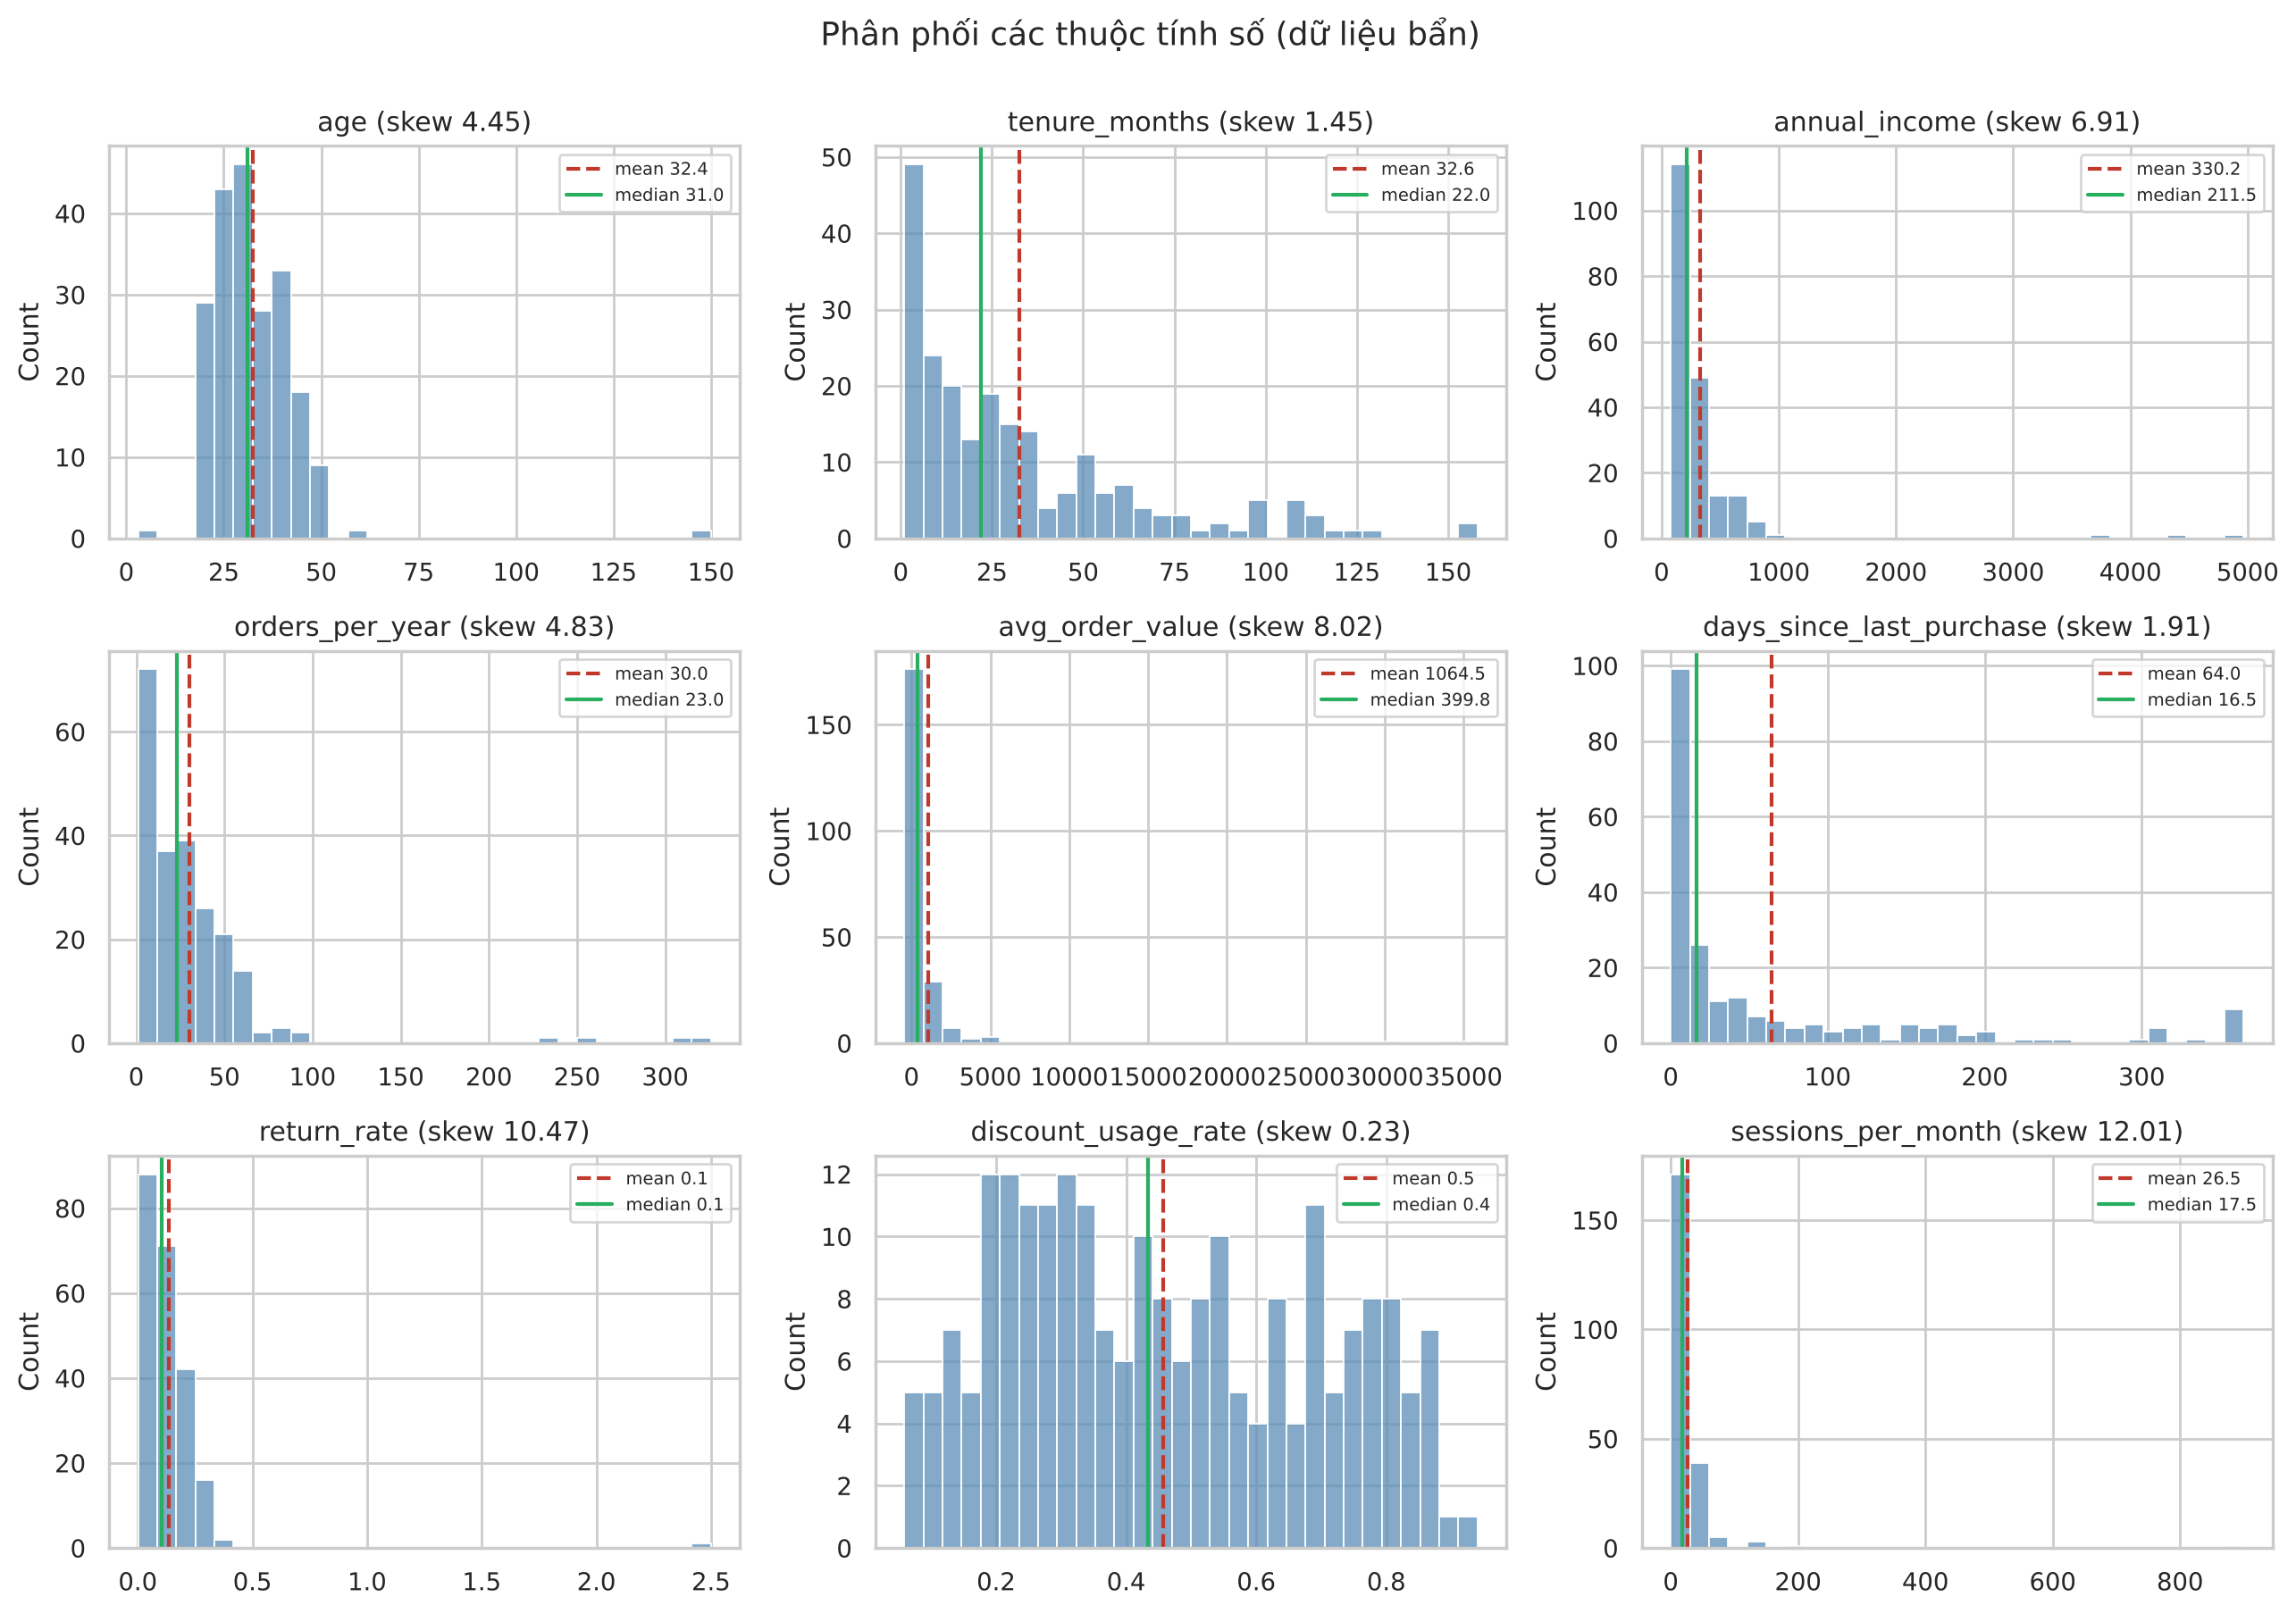

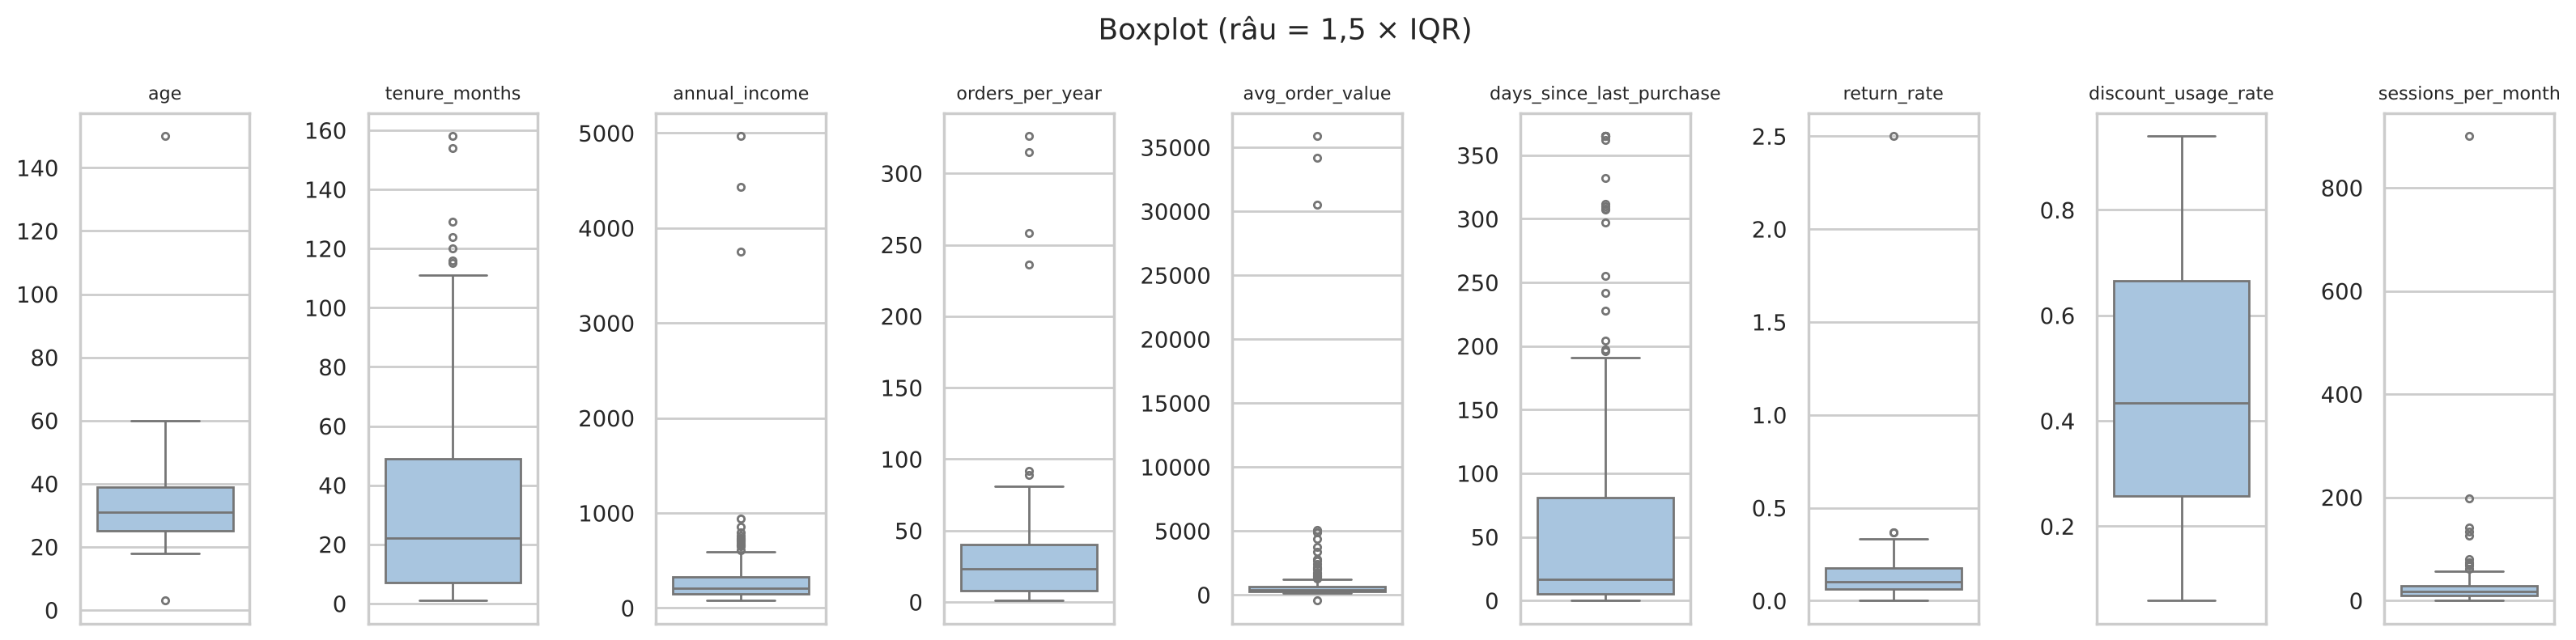

In [4]:
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, col in zip(axes.flat, NUM_COLS):
    x = df[col].dropna().astype(float)
    sns.histplot(x, bins=30, ax=ax, color="#5b8db8")
    ax.axvline(x.mean(), color="#c0392b", ls="--", label=f"mean {x.mean():.1f}")
    ax.axvline(x.median(), color="#27ae60", ls="-", label=f"median {x.median():.1f}")
    ax.set_title(f"{col} (skew {stats.skew(x):.2f})"); ax.set_xlabel(""); ax.legend(fontsize=7)
fig.suptitle("Phân phối các thuộc tính số (dữ liệu bẩn)", y=1.0); fig.tight_layout()
savefig(fig, "b_hist_numeric.png"); plt.show()

fig, axes = plt.subplots(1, 9, figsize=(16, 4))
for ax, col in zip(axes, NUM_COLS):
    sns.boxplot(y=df[col].astype(float), ax=ax, color="#9fc5e8", flierprops=dict(markersize=3))
    ax.set_title(col, fontsize=8); ax.set_ylabel("")
fig.suptitle("Boxplot (râu = 1,5 × IQR)"); fig.tight_layout()
savefig(fig, "b_box_numeric.png"); plt.show()

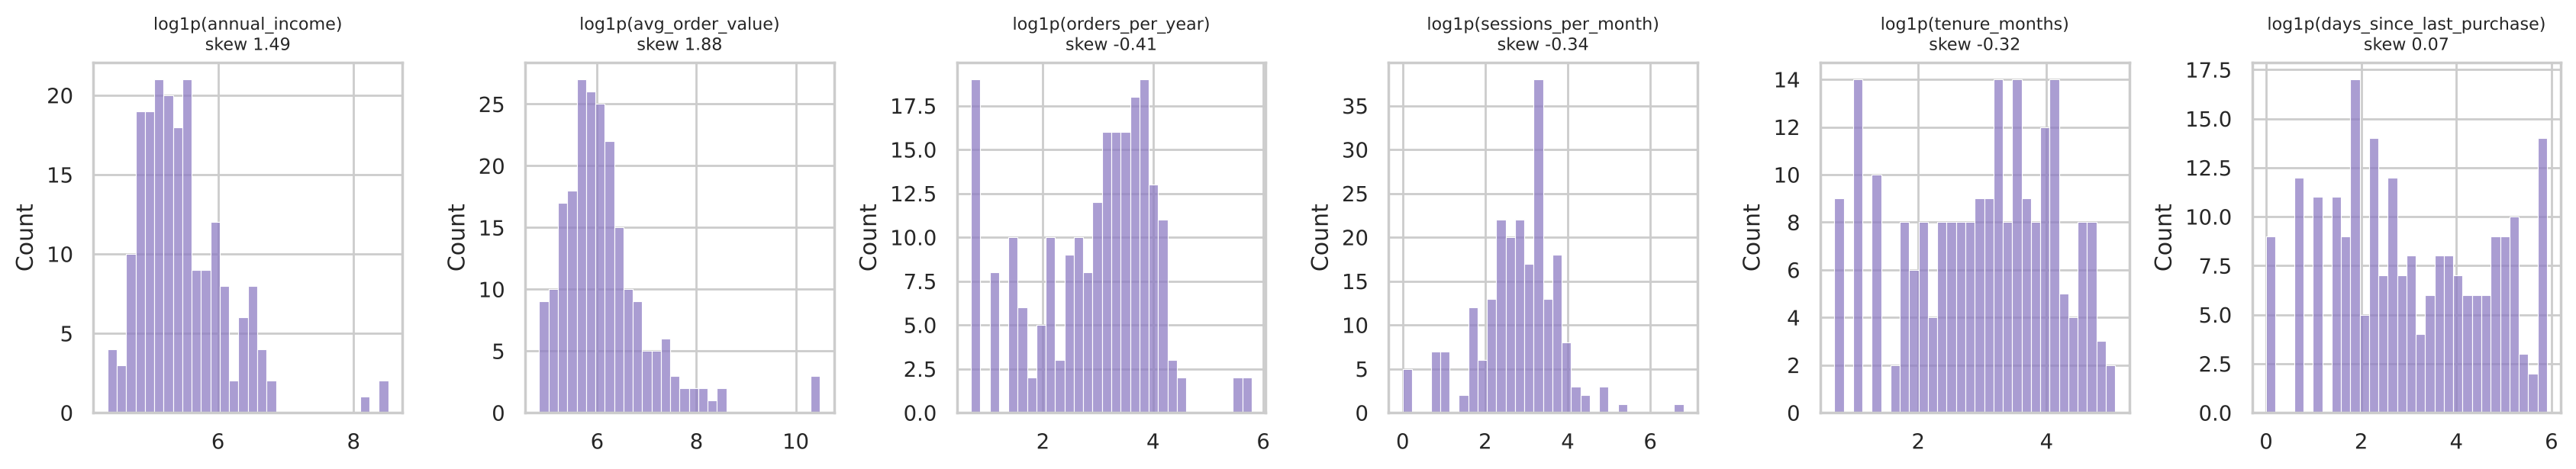

,skew_goc,skew_log1p
annual_income,6.91,1.49
avg_order_value,8.02,1.88
orders_per_year,4.83,-0.41
sessions_per_month,12.01,-0.34
tenure_months,1.45,-0.32
days_since_last_purchase,1.91,0.07


In [5]:
# Cac cot lech phai, duong: xem lai tren thang log (chi lay gia tri > 0)
LOG_COLS = ["annual_income", "avg_order_value", "orders_per_year", "sessions_per_month",
            "tenure_months", "days_since_last_purchase"]
fig, axes = plt.subplots(1, 6, figsize=(17, 3.2))
skew_log = {}
for ax, col in zip(axes, LOG_COLS):
    x = df[col].dropna().astype(float); x = np.log1p(x[x >= 0])
    skew_log[col] = stats.skew(x)
    sns.histplot(x, bins=30, ax=ax, color="#8e7cc3"); ax.set_title(f"log1p({col})\nskew {skew_log[col]:.2f}", fontsize=8)
    ax.set_xlabel("")
fig.tight_layout(); savefig(fig, "b_hist_log.png"); plt.show()
pd.DataFrame({"skew_goc": b2.loc[LOG_COLS, "skewness"], "skew_log1p": pd.Series(skew_log)}).round(2)

**Nhận xét B2.**

- **Lệch phải mạnh ở hầu hết thuộc tính số.** Tỷ lệ mean/median của AOV là 2,66; recency là 3,88; skewness của AOV là 8,0, của sessions là 12,0. Đúng như ví dụ lương trong giáo trình, mean không đại diện tốt; median và trimmed mean ổn định hơn (AOV: mean 1.064, trimmed mean 522, median 400).
- **Midrange bị ngoại lai chi phối hoàn toàn**: midrange của AOV là 17.713, gấp 44 lần median; của sessions là 450 so với median 17,5.
- **Có giá trị bất khả hiện ngay trong min/max**: age min 3 và max 150, AOV min −450, return_rate max 2,5, sessions max 900.
- **Biến đổi log1p giảm độ lệch rõ rệt**: skewness của orders từ 4,83 về −0,41; sessions từ 12,0 về −0,34; recency từ 1,91 về 0,07. Income và AOV vẫn còn lệch sau log (1,49 và 1,88) vì các giá trị cực trị vẫn rất xa sau log, gợi ý đây là các điểm cực trị thật, không chỉ do phân phối lệch.
- discount_usage_rate gần đối xứng (skew 0,23), không có điểm vượt ngưỡng IQR.

## B3. Phân tích đơn biến: thuộc tính danh mục

Với nominal chỉ mode có nghĩa; với ordinal (membership_tier) có thêm median.

Median membership_tier: Silver


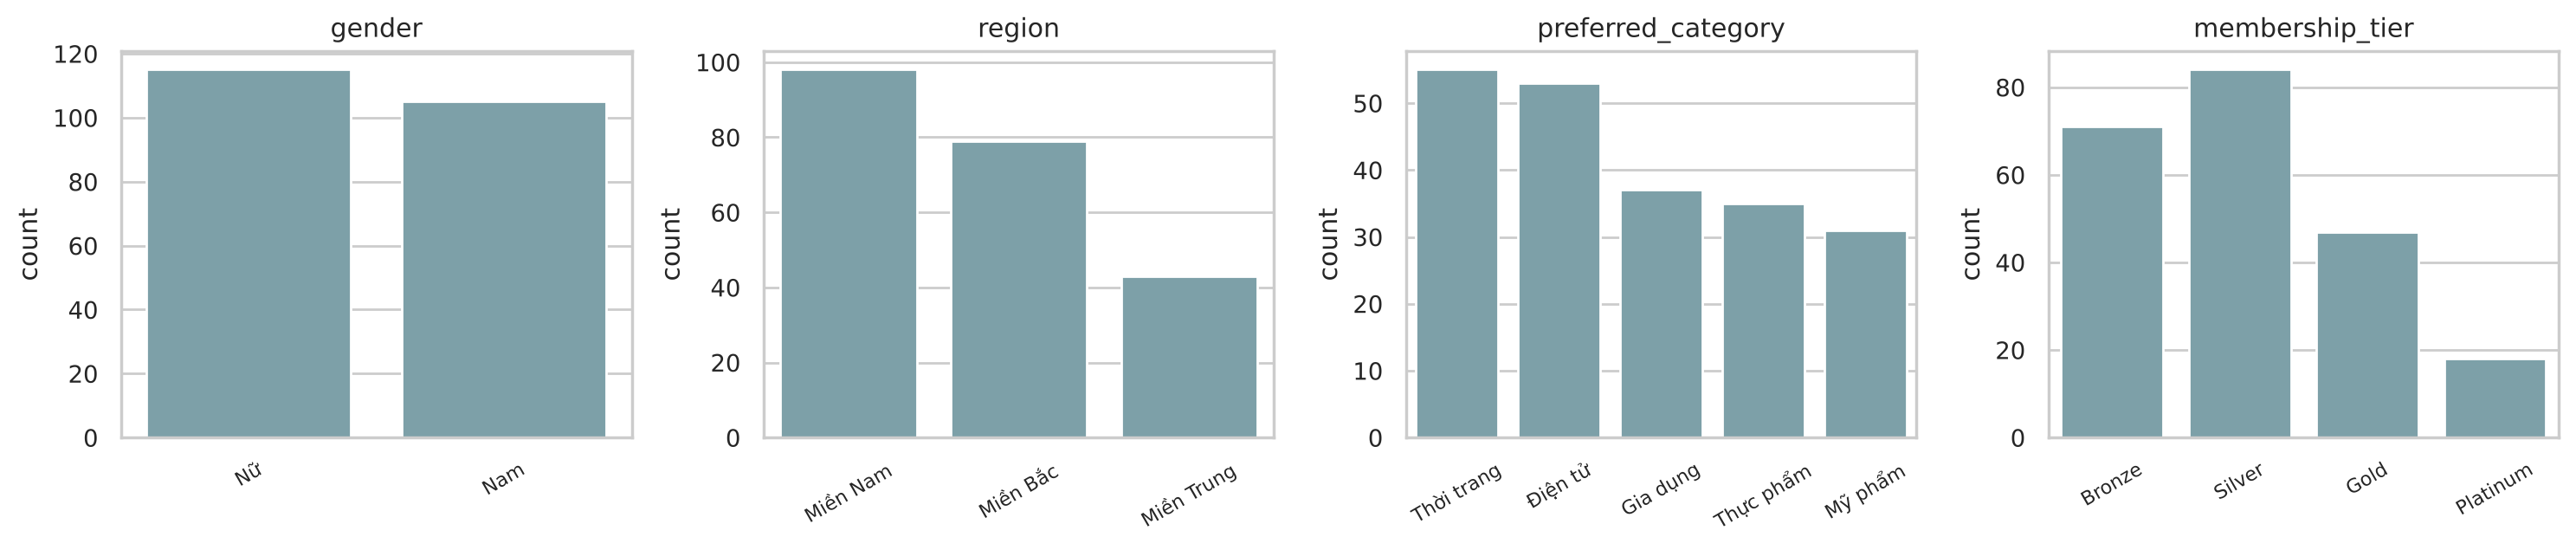

,thuoc_tinh,so_lop,mode,ty_le_mode,ty_le_lop_nho_nhat,lon/nho,so_thieu
0,gender,2,Nữ,0.523,0.477,1.10,0
1,region,3,Miền Nam,0.445,0.195,2.28,0
2,preferred_category,5,Thời trang,0.261,0.147,1.77,9
3,membership_tier,4,Silver,0.382,0.082,4.67,0


In [6]:
rows = []
for col in CAT_COLS:
    vc = df[col].value_counts()
    rows.append({"thuoc_tinh": col, "so_lop": len(vc), "mode": vc.index[0],
                 "ty_le_mode": round(vc.iloc[0] / vc.sum(), 3),
                 "ty_le_lop_nho_nhat": round(vc.iloc[-1] / vc.sum(), 3),
                 "lon/nho": round(vc.iloc[0] / vc.iloc[-1], 2), "so_thieu": df[col].isna().sum()})
b3 = pd.DataFrame(rows)
tiers = ORDINAL_COLS["membership_tier"]
tier_code = df.membership_tier.map({t: i for i, t in enumerate(tiers)})
print("Median membership_tier:", tiers[int(tier_code.median())])

fig, axes = plt.subplots(1, 4, figsize=(15, 3.3))
for ax, col in zip(axes, CAT_COLS):
    order = tiers if col == "membership_tier" else df[col].value_counts().index
    sns.countplot(x=df[col], order=order, ax=ax, color="#76a5af")
    ax.set_title(col); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=30, labelsize=8)
fig.tight_layout(); savefig(fig, "b_bar_categorical.png"); plt.show()
b3

**Nhận xét B3.** gender gần cân bằng (52/48). region lệch vừa (Miền Nam 44,5%, Miền Trung 19,5%). membership_tier mất cân bằng nhất: Silver 38,2%, lớp nhỏ nhất chỉ 8,2% (tỷ lệ 4,7 lần); median hạng là Silver. preferred_category có 9 giá trị thiếu, các lớp không quá chênh lệch (1,77 lần).

## B4. Quan hệ giữa các thuộc tính

Pearson nhạy với ngoại lai và chỉ đo quan hệ tuyến tính; Spearman dựa trên hạng nên bền vững hơn. Ma trận **|Spearman − Pearson|** chỉ ra các cặp mà ngoại lai hoặc quan hệ phi tuyến làm Pearson sai lệch. Tương quan được tính trên các cặp quan sát đủ (pairwise).

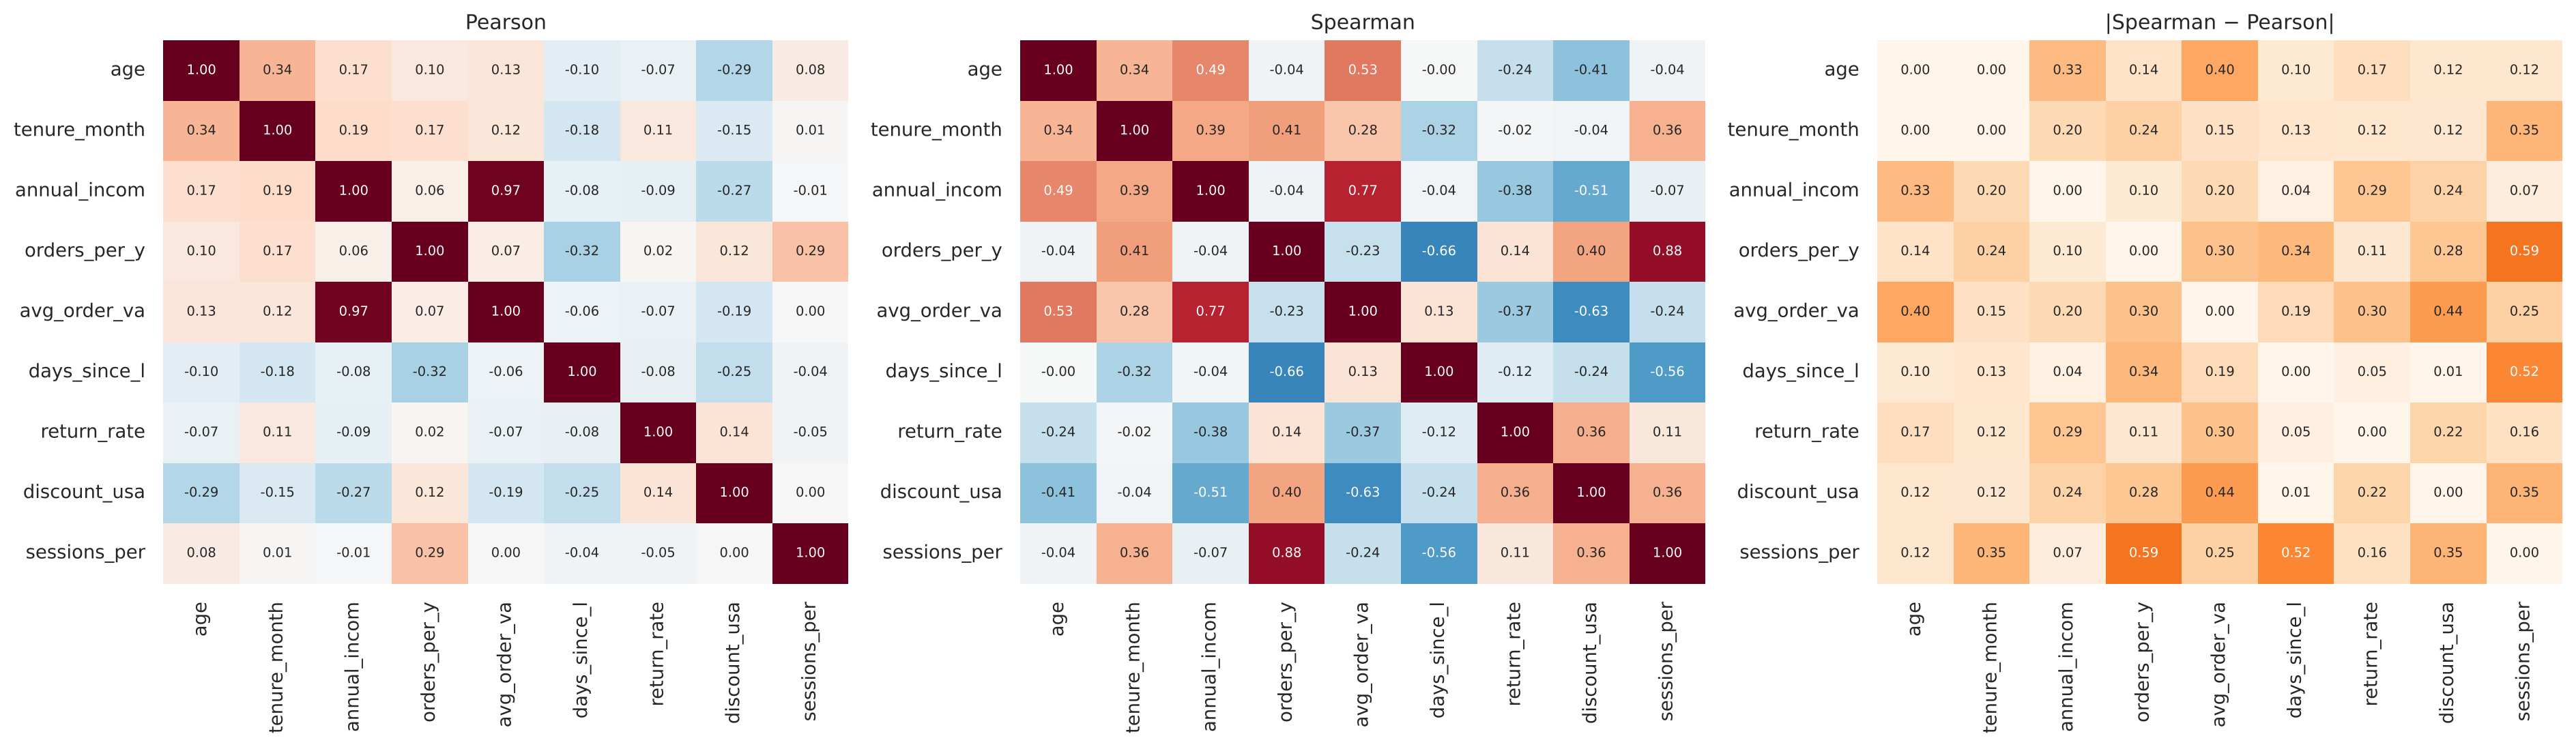

Cac cap |Spearman| >= 0.5 hoac chenh lech >= 0.2:


,x,y,pearson,spearman,chenh
25,orders_per_year,sessions_per_month,0.290,0.879,0.588
32,days_since_last_purchase,sessions_per_month,-0.039,-0.563,0.524
28,avg_order_value,discount_usage_rate,-0.185,-0.628,0.442
3,age,avg_order_value,0.127,0.529,0.401
35,discount_usage_rate,sessions_per_month,0.003,0.356,0.353
14,tenure_months,sessions_per_month,0.011,0.358,0.347
22,orders_per_year,days_since_last_purchase,-0.323,-0.659,0.336
1,age,annual_income,0.166,0.492,0.325
27,avg_order_value,return_rate,-0.069,-0.371,0.302
21,orders_per_year,avg_order_value,0.072,-0.228,0.301


In [7]:
num = df[NUM_COLS].astype(float)
pear, spear = num.corr("pearson"), num.corr("spearman")
diff = (spear - pear).abs()
fig, axes = plt.subplots(1, 3, figsize=(19, 5.6))
short = [c[:12] for c in NUM_COLS]
for ax, m, t, cmap, vr in [(axes[0], pear, "Pearson", "RdBu_r", (-1, 1)),
                           (axes[1], spear, "Spearman", "RdBu_r", (-1, 1)),
                           (axes[2], diff, "|Spearman − Pearson|", "Oranges", (0, 1))]:
    sns.heatmap(m, annot=True, fmt=".2f", cmap=cmap, vmin=vr[0], vmax=vr[1], ax=ax,
                xticklabels=short, yticklabels=short, annot_kws={"size": 7}, cbar=False)
    ax.set_title(t)
fig.tight_layout(); savefig(fig, "b_corr_heatmaps.png"); plt.show()

iu = np.triu_indices(len(NUM_COLS), 1)
pairs = pd.DataFrame({"x": [NUM_COLS[i] for i in iu[0]], "y": [NUM_COLS[j] for j in iu[1]],
                      "pearson": pear.values[iu], "spearman": spear.values[iu], "chenh": diff.values[iu]})
pairs.to_csv(TABLES / "b4_correlation_pairs.csv", index=False)
print("Cac cap |Spearman| >= 0.5 hoac chenh lech >= 0.2:")
pairs[(pairs.spearman.abs() >= 0.5) | (pairs.chenh >= 0.2)].sort_values("chenh", ascending=False).round(3)

In [8]:
# Pearson tren thang goc va thang log cho cac cap lech phai
def pear_log(x, y):
    d = df[[x, y]].astype(float).dropna(); d = d[(d > 0).all(axis=1)]
    return stats.pearsonr(np.log(d[x]), np.log(d[y]))[0]
key = [("annual_income", "avg_order_value"), ("orders_per_year", "sessions_per_month"),
       ("orders_per_year", "days_since_last_purchase"), ("annual_income", "orders_per_year")]
pd.DataFrame([{"cap": f"{x} – {y}", "pearson_goc": pear.loc[x, y], "pearson_log": pear_log(x, y),
               "spearman": spear.loc[x, y]} for x, y in key]).round(3)

,cap,pearson_goc,pearson_log,spearman
0,annual_income – avg_order_value,0.972,0.868,0.771
1,orders_per_year – sessions_per_month,0.290,0.791,0.879
2,orders_per_year – days_since_last_purchase,-0.323,-0.662,-0.659
3,annual_income – orders_per_year,0.061,0.118,-0.041


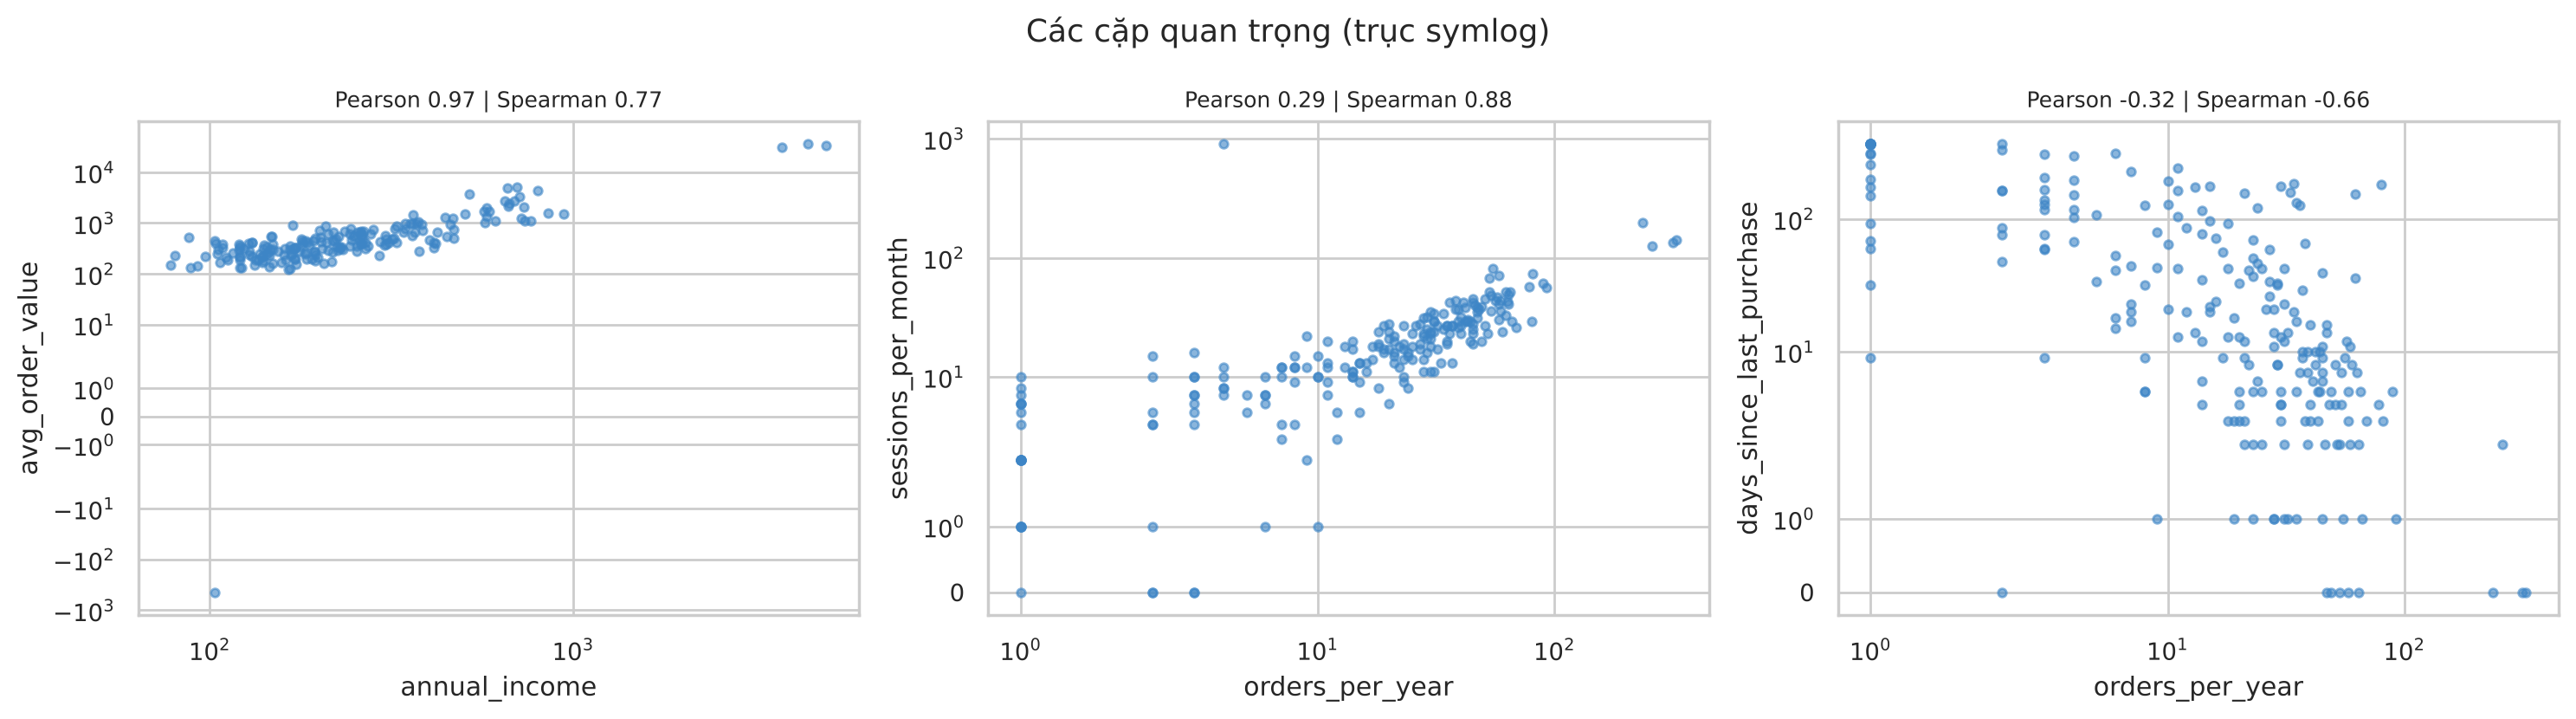

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (x, y) in zip(axes, key[:3]):
    d = df[[x, y]].astype(float).dropna()
    ax.scatter(d[x], d[y], s=12, alpha=.6, color="#3d85c6")
    ax.set_xscale("symlog"); ax.set_yscale("symlog")
    ax.set_xlabel(x); ax.set_ylabel(y)
    ax.set_title(f"Pearson {pear.loc[x, y]:.2f} | Spearman {spear.loc[x, y]:.2f}", fontsize=9)
fig.suptitle("Các cặp quan trọng (trục symlog)"); fig.tight_layout()
savefig(fig, "b_scatter_pairs.png"); plt.show()

### Quan hệ giữa các thuộc tính danh mục: kiểm định χ²

H₀: hai thuộc tính độc lập. Kèm Cramér's V để đo độ mạnh (χ² phụ thuộc cỡ mẫu) và cảnh báo khi có ô kỳ vọng < 5 (điều kiện áp dụng xấp xỉ χ²).

In [10]:
rows = []
for i, x in enumerate(CAT_COLS):
    for y in CAT_COLS[i + 1:]:
        t = pd.crosstab(df[x], df[y])
        chi2, p, dof, exp = stats.chi2_contingency(t)
        v = np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))
        rows.append({"cap": f"{x} × {y}", "chi2": chi2, "df": dof, "p": p, "cramers_v": v,
                     "o_ky_vong<5": int((exp < 5).sum()), "tong_o": exp.size})
b4_chi = pd.DataFrame(rows).sort_values("p"); b4_chi.to_csv(TABLES / "b4_chi2.csv", index=False)
b4_chi.round(4)

,cap,chi2,df,p,cramers_v,o_ky_vong<5,tong_o
5,preferred_category × membership_tier,30.2730,12,0.0025,0.2187,5,20
4,region × membership_tier,7.9295,6,0.2433,0.1342,1,12
3,region × preferred_category,9.6329,8,0.2917,0.1511,0,15
1,gender × preferred_category,3.4505,4,0.4854,0.1279,0,10
0,gender × region,0.5953,2,0.7426,0.0520,0,6
2,gender × membership_tier,0.5211,3,0.9142,0.0487,0,8


Spearman(tier, orders x AOV): 0.885


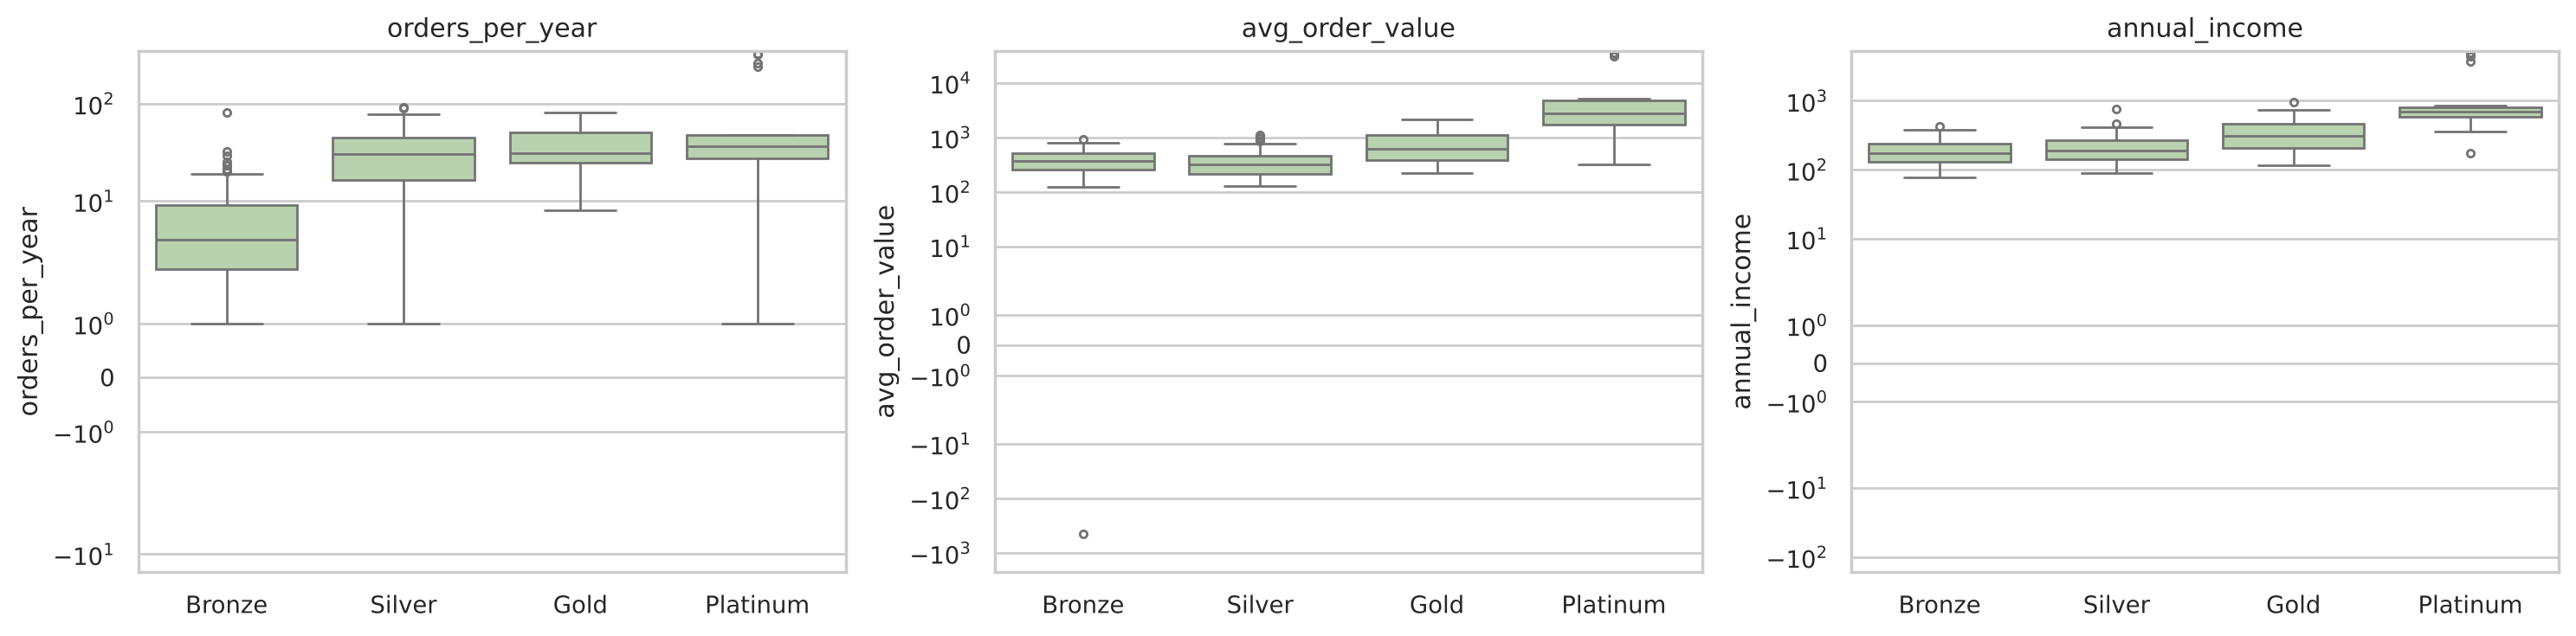

,orders_per_year,avg_order_value,annual_income
membership_tier,,,
Bronze,4.0,370.5,172.4
Silver,30.0,312.2,187.9
Gold,31.0,601.9,312.6
Platinum,36.5,2718.0,687.2


In [11]:
# Thuoc tinh so theo hang thanh vien (ordinal) va tuong quan Spearman voi tong chi tieu
spend = (df.orders_per_year * df.avg_order_value).astype(float)
print("Spearman(tier, orders x AOV):", round(stats.spearmanr(tier_code, spend, nan_policy="omit")[0], 3))
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col in zip(axes, ["orders_per_year", "avg_order_value", "annual_income"]):
    sns.boxplot(x=df.membership_tier, y=df[col].astype(float), order=tiers, ax=ax, color="#b6d7a8",
                flierprops=dict(markersize=3))
    ax.set_yscale("symlog"); ax.set_title(col); ax.set_xlabel("")
fig.tight_layout(); savefig(fig, "b_box_by_tier.png"); plt.show()
df.groupby("membership_tier")[["orders_per_year", "avg_order_value", "annual_income"]].median().loc[tiers].round(1)

**Nhận xét B4.**

- **Pearson bị ngoại lai bóp méo nghiêm trọng.** orders – sessions: Pearson chỉ 0,29 nhưng Spearman 0,88, và Pearson trên thang log là 0,79. Một giá trị sessions = 900 đủ làm Pearson sai lệch. Ngược lại, income – AOV có Pearson 0,97, *cao hơn* Spearman 0,77: vài khách có cả thu nhập và AOV cực lớn tạo ra một quan hệ tuyến tính "giả" do điểm đòn bẩy. Hai ví dụ này cho thấy với dữ liệu này, **Spearman đáng tin hơn Pearson**.
- **Quan hệ phi tuyến**: orders – recency có Pearson −0,32, Spearman −0,66 (quan hệ nghịch, đơn điệu nhưng không tuyến tính).
- **Thuộc tính dư thừa**: orders – sessions (Spearman 0,88) và membership_tier với tổng chi tiêu orders × AOV (Spearman 0,885). Median AOV của Platinum gấp khoảng 7 lần Bronze. Nếu giữ cả ba, khía cạnh "mức chi tiêu/hoạt động" sẽ bị tính trọng số nhiều lần trong khoảng cách.
- **Nhiều tương quan có thể là "biến thứ ba"**: AOV – discount (Spearman −0,63), age – AOV (0,53), age – income (0,49). Có thể do tồn tại các nhóm khách khác nhau (ví dụ nhóm trẻ, săn khuyến mãi, chi tiêu ít) chứ không phải tuổi *gây ra* chi tiêu cao. Đây chính là dấu hiệu dữ liệu có cấu trúc nhóm, điều mà phân cụm cần tìm.
- **χ² giữa các thuộc tính danh mục**: chỉ preferred_category × membership_tier có ý nghĩa (p = 0,0025, Cramér's V = 0,22, liên hệ yếu đến vừa), nhưng 5/20 ô có tần số kỳ vọng < 5 nên kết quả cần thận trọng. gender và region không liên hệ với thuộc tính danh mục nào (mọi p > 0,24); cùng với B2 (không liên hệ rõ với thuộc tính số), hai thuộc tính này **nhiều khả năng không mang cấu trúc cụm**.

## B5. Giá trị thiếu

Kiểm tra cơ chế thiếu: với mỗi cột có giá trị thiếu, so sánh phân phối các thuộc tính khác giữa nhóm *thiếu* và *không thiếu*. Thuộc tính số dùng **Mann-Whitney U** (phi tham số, phù hợp dữ liệu lệch, không đòi hỏi phân phối chuẩn); thuộc tính danh mục dùng χ². Do thực hiện nhiều kiểm định cùng lúc, p-value được hiệu chỉnh **Holm** để tránh kết luận sai do so sánh bội.

- Không có khác biệt đáng kể: phù hợp với MCAR (không chứng minh được MCAR, chỉ là không bác bỏ).
- Có khác biệt theo biến quan sát được: dấu hiệu MAR.
- MNAR (thiếu phụ thuộc chính giá trị bị thiếu) không kiểm định được từ dữ liệu.

So dong thieu >= 2 cot: 4
Dong thoi thieu (so dong):
                    age  annual_income  preferred_category
age                  11              1                   1
annual_income         1             22                   2
preferred_category    1              2                   9


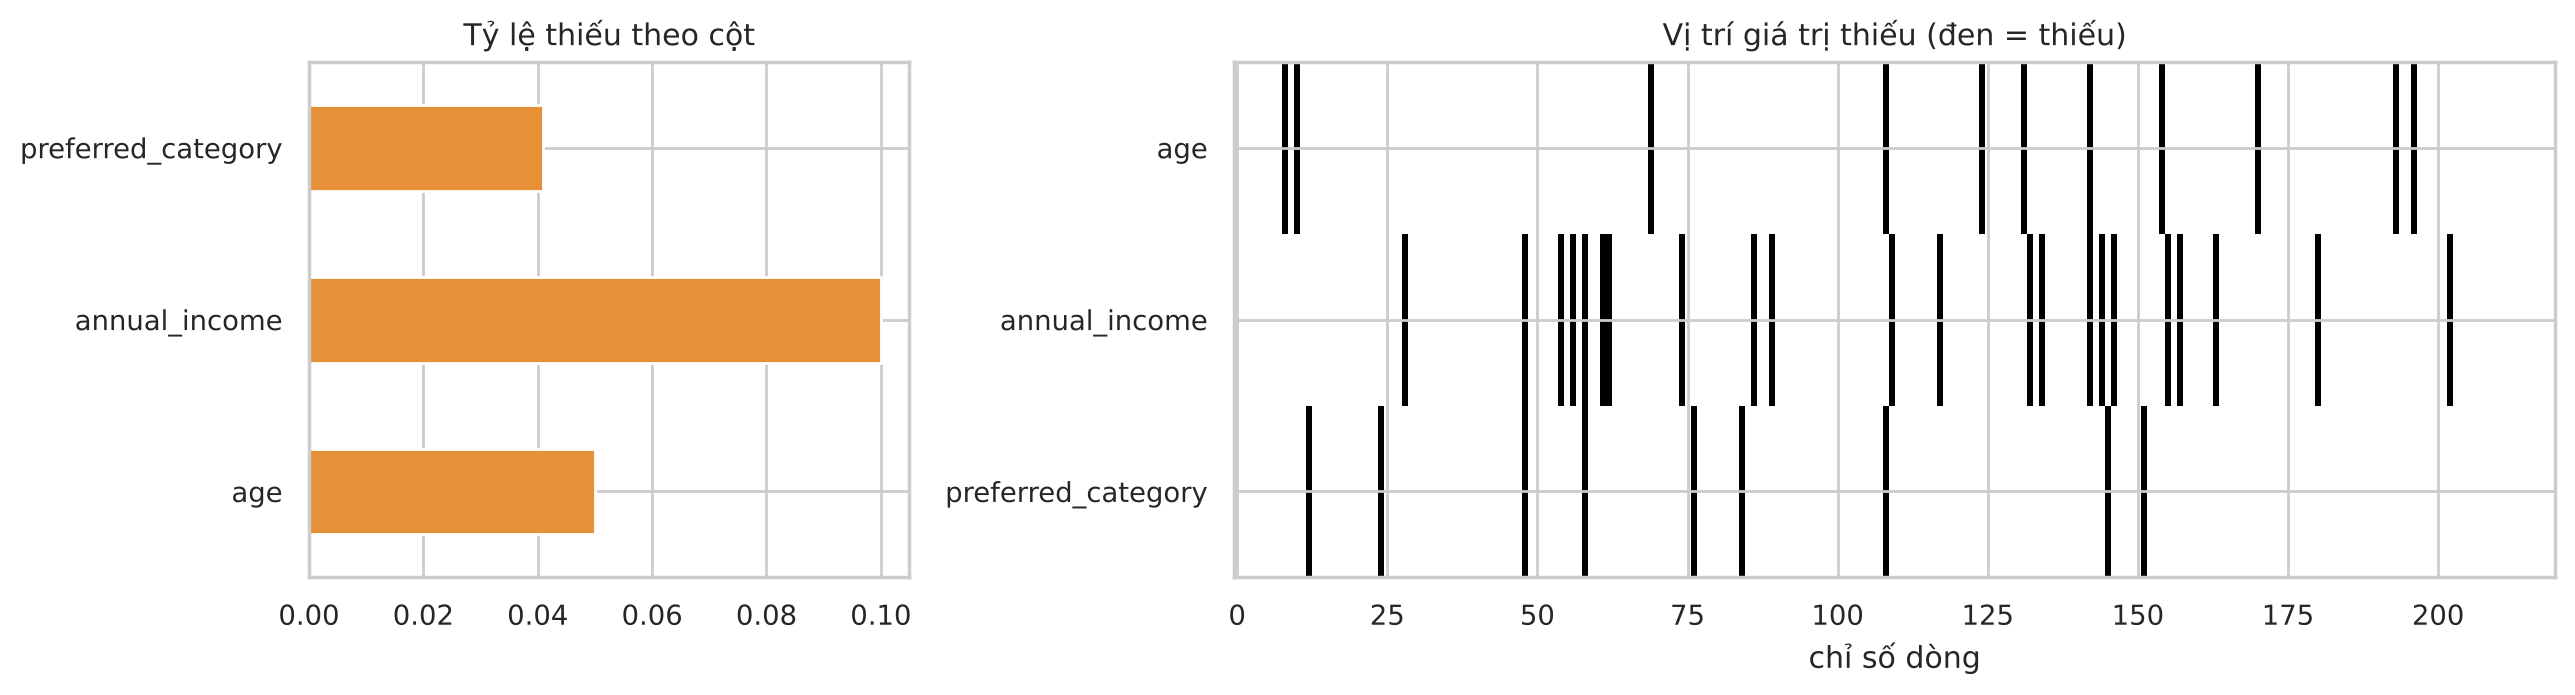

,so_thieu,ty_le
age,11,0.050
annual_income,22,0.100
preferred_category,9,0.041


In [12]:
miss = df[INPUT_COLS].isna()
miss_cols = miss.columns[miss.any()].tolist()
b5 = pd.DataFrame({"so_thieu": miss.sum()[miss_cols], "ty_le": miss.mean()[miss_cols].round(3)})
print("So dong thieu >= 2 cot:", (miss.sum(axis=1) >= 2).sum())
print("Dong thoi thieu (so dong):"); print((miss[miss_cols].T.astype(int) @ miss[miss_cols].astype(int)))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 2.2]})
b5.ty_le.plot.barh(ax=axes[0], color="#e69138"); axes[0].set_title("Tỷ lệ thiếu theo cột")
axes[1].imshow(miss[miss_cols].T.astype(int), aspect="auto", cmap="Greys", interpolation="nearest")
axes[1].set_yticks(range(len(miss_cols))); axes[1].set_yticklabels(miss_cols)
axes[1].set_xlabel("chỉ số dòng"); axes[1].set_title("Vị trí giá trị thiếu (đen = thiếu)")
fig.tight_layout(); savefig(fig, "b_missing.png"); plt.show()
b5

In [13]:
def holm(p):
    p = np.asarray(p); o = np.argsort(p); m = len(p); adj = np.empty(m)
    adj[o] = np.minimum(1, np.maximum.accumulate((m - np.arange(m)) * p[o]))
    return adj

rows = []
for mc in miss_cols:
    ind = df[mc].isna()
    for col in NUM_COLS:
        if col == mc: continue
        a, b_ = df.loc[ind, col].dropna().astype(float), df.loc[~ind, col].dropna().astype(float)
        rows.append({"cot_thieu": mc, "bien_so_sanh": col, "kiem_dinh": "Mann-Whitney",
                     "median_thieu": a.median(), "median_khong_thieu": b_.median(),
                     "p": stats.mannwhitneyu(a, b_).pvalue})
    for col in CAT_COLS:
        if col == mc: continue
        t = pd.crosstab(ind, df[col])
        rows.append({"cot_thieu": mc, "bien_so_sanh": col, "kiem_dinh": "chi2",
                     "p": stats.chi2_contingency(t)[1]})
mech = pd.DataFrame(rows); mech["p_holm"] = holm(mech.p)
mech.to_csv(TABLES / "b5_missing_mechanism.csv", index=False)
print("Tong so kiem dinh:", len(mech))
print("Cac kiem dinh co p < 0.05 (truoc hieu chinh):")
mech[mech.p < 0.05].sort_values("p").round(4)

Tong so kiem dinh: 36
Cac kiem dinh co p < 0.05 (truoc hieu chinh):


,cot_thieu,bien_so_sanh,kiem_dinh,median_thieu,median_khong_thieu,p,p_holm
12,annual_income,age,Mann-Whitney,28.0,32.0,0.0018,0.0639
13,annual_income,tenure_months,Mann-Whitney,7.0,24.0,0.0018,0.0639
23,annual_income,membership_tier,chi2,NaN,NaN,0.0112,0.3825
19,annual_income,sessions_per_month,Mann-Whitney,8.0,18.0,0.0175,0.5787
14,annual_income,orders_per_year,Mann-Whitney,8.0,24.0,0.0224,0.7164


**Nhận xét B5.**

- 3 cột thiếu: age 11 (5,0%), annual_income 22 (10,0%), preferred_category 9 (4,1%). Thiếu phân tán, chỉ 4 dòng thiếu ≥ 2 cột, nên không có mẫu thiếu theo khối.
- **age và preferred_category**: không có kiểm định nào có p < 0,05, phù hợp với MCAR.
- **annual_income**: nhóm thiếu thu nhập có tenure thấp hơn rõ (median 7 tháng so với 24 tháng, p = 0,0018), cũng ít đơn, ít phiên truy cập và tuổi trẻ hơn: đây là chân dung khách mới. **Tuy nhiên sau hiệu chỉnh Holm cho 36 kiểm định, p_holm = 0,064, không còn có ý nghĩa ở mức 0,05.** Kết luận trung thực: *có dấu hiệu* MAR theo tenure (nhất quán trên nhiều biến cùng hướng), nhưng chưa đủ bằng chứng thống kê do chỉ có 22 giá trị thiếu.
- **Hệ quả:** không nên xóa dòng thiếu income (mất 10% dữ liệu và có nguy cơ mất bớt nhóm khách mới). Cách điền nên tận dụng các biến liên quan (tenure, orders) thay vì điền một hằng số chung.

## B6. Ngoại lai và nhiễu

Năm phương pháp, từ đơn giản đến phức tạp:

1. **Kiểm tra ràng buộc** miền giá trị và logic nghiệp vụ.
2. **IQR 1,5 và 3,0** trên thang gốc (quy tắc boxplot).
3. **IQR 1,5 trên thang log1p** cho các cột lệch phải.
4. **z-score** |z| > 3.
5. **LOF** (Local Outlier Factor, đa biến, dựa trên mật độ k láng giềng gần nhất).

In [14]:
# (1) Rang buoc: tung dong vi pham
viol = pd.DataFrame({
    "age ngoai [18,70]": ~df.age.between(18, 70) & df.age.notna(),
    "ty le ngoai [0,1]": ~df.return_rate.between(0, 1) | ~df.discount_usage_rate.between(0, 1),
    "AOV <= 0": df.avg_order_value <= 0,
    "sessions > 24*30 hoac < 0": ~df.sessions_per_month.between(0, 720),
    "recency ngoai [0,365]": ~df.days_since_last_purchase.between(0, 365),
    "tenure > (age-16)*12": (df.tenure_months > (df.age - 16) * 12) & df.age.notna(),
    "orders >= 50 nhung recency >= 120": (df.orders_per_year >= 50) & (df.days_since_last_purchase >= 120),
})
SOFT = ["orders >= 50 nhung recency >= 120"]          # rang buoc mem: dang ngo, khong bat kha
HARD = [c_ for c_ in viol.columns if c_ not in SOFT]
viol_rows = viol[HARD].any(axis=1); soft_rows = viol[SOFT].any(axis=1)
print("So vi pham moi rang buoc:"); print(viol.sum()[lambda s: s > 0])
df.loc[viol_rows, [ID_COL] + INPUT_COLS]

So vi pham moi rang buoc:
age ngoai [18,70]                    2
ty le ngoai [0,1]                    1
AOV <= 0                             1
sessions > 24*30 hoac < 0            1
tenure > (age-16)*12                 2
orders >= 50 nhung recency >= 120    2
dtype: int64


,customer_id,age,gender,region,membership_tier,tenure_months,annual_income,orders_per_year,avg_order_value,days_since_last_purchase,return_rate,discount_usage_rate,sessions_per_month,preferred_category
110,C0111,38.0,Nữ,Miền Nam,Gold,115,263.2,30,482.0,4,2.500,0.293,11,Điện tử
166,C0167,43.0,Nam,Miền Trung,Bronze,11,180.7,4,420.4,196,0.001,0.215,900,Thời trang
167,C0168,150.0,Nam,Miền Nam,Silver,107,171.5,14,328.5,6,0.067,0.526,11,Thực phẩm
171,C0172,3.0,Nam,Miền Nam,Bronze,1,103.4,4,438.4,102,0.097,0.396,10,Gia dụng
210,C0211,18.0,Nam,Miền Nam,Silver,96,201.0,1,530.7,365,0.196,0.321,6,Điện tử
219,C0220,23.0,Nam,Miền Bắc,Bronze,22,103.1,32,-450.0,1,0.205,0.520,27,Mỹ phẩm


Ghi chú về các ràng buộc: ràng buộc được chia hai mức.

- **Ràng buộc cứng** (vi phạm là bất khả): miền giá trị, và tenure > (age − 16) × 12 (không thể gắn bó với sàn từ trước 16 tuổi).
- **Ràng buộc mềm** (vi phạm là *đáng ngờ*, không phải bất khả): người mua ≥ 50 đơn/năm nhưng ≥ 120 ngày chưa mua. Trường hợp này có thể là lỗi dữ liệu, nhưng cũng có thể là khách *trước đây mua nhiều và nay đã ngừng*, tức khách có nguy cơ rời bỏ thật. Ngưỡng 50 và 120 do người phân tích đặt ra, mang tính chủ quan. Hạng thành viên mâu thuẫn với chi tiêu được kiểm tra riêng ở dưới vì có thể do quy tắc xếp hạng của sàn (ví dụ xếp hạng theo chi tiêu tích lũy).

In [15]:
# Hang thanh vien mau thuan voi chi tieu: tier cao nhat nhung chi tieu thuoc 10% thap nhat
low_spend = spend <= spend.quantile(0.10)
tier_conflict = (df.membership_tier == "Platinum") & low_spend
print("Platinum nhung chi tieu thuoc 10% thap nhat:", tier_conflict.sum())
df.loc[tier_conflict, [ID_COL, "membership_tier", "orders_per_year", "avg_order_value", "tenure_months"]]

Platinum nhung chi tieu thuoc 10% thap nhat: 1


,customer_id,membership_tier,orders_per_year,avg_order_value,tenure_months
51,C0052,Platinum,1,320.2,2


In [16]:
# (2)-(4) IQR goc, IQR log, z-score: so o bi gan co theo cot
flag_iqr15 = iqr_flags(df, NUM_COLS, 1.5)
flag_iqr30 = iqr_flags(df, NUM_COLS, 3.0)
logdf = df[NUM_COLS].astype(float).copy()
for col in LOG_COLS:
    logdf[col] = np.log1p(logdf[col].where(logdf[col] >= 0))   # gia tri am da bi bat o (1)
flag_iqrlog = iqr_flags(logdf, NUM_COLS, 1.5)
z = (num - num.mean()) / num.std()
flag_z = z.abs() > 3
b6_counts = pd.DataFrame({"IQR 1.5 goc": flag_iqr15.sum(), "IQR 3.0 goc": flag_iqr30.sum(),
                          "IQR 1.5 log": flag_iqrlog.sum(), "|z| > 3": flag_z.sum()})
b6_counts.loc["SO DONG bi gan co"] = [f.any(axis=1).sum() for f in (flag_iqr15, flag_iqr30, flag_iqrlog, flag_z)]
b6_counts

,IQR 1.5 goc,IQR 3.0 goc,IQR 1.5 log,|z| > 3
age,2,1,2,1
tenure_months,7,0,0,2
annual_income,18,4,3,3
orders_per_year,6,4,0,4
avg_order_value,25,15,10,3
days_since_last_purchase,21,12,0,9
return_rate,3,1,3,1
discount_usage_rate,0,0,0,0
sessions_per_month,10,5,7,1
SO DONG bi gan co,64,31,21,21


In [17]:
# Hieu ung che khuat (masking) cua z-score: mot gia tri cuc tri lam phong std
s_ = df.sessions_per_month.astype(float)
for lab, x in [("co gia tri max", s_), ("bo gia tri max", s_[s_ < s_.max()])]:
    print(f"sessions {lab}: mean={x.mean():.1f}, std={x.std():.1f}, nguong z=3: {x.mean() + 3 * x.std():.1f}")

sessions co gia tri max: mean=26.5, std=63.6, nguong z=3: 217.3
sessions bo gia tri max: mean=22.5, std=23.4, nguong z=3: 92.7


So dong LOF gan co (threshold mac dinh, LOF > 1.5): k=10: 7 | k=20: 7 | k=30: 7
Do on dinh: dong bi gan co o ca 3 gia tri k: 7


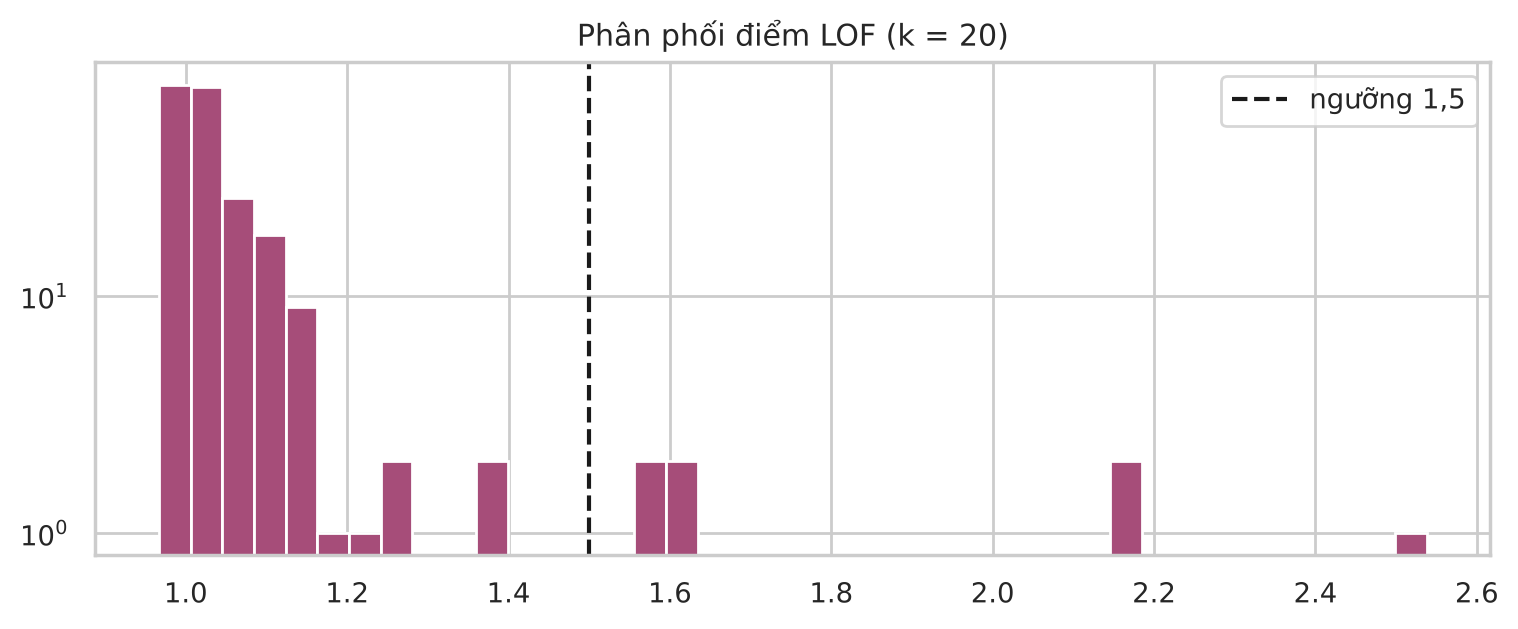

In [18]:
# (5) LOF tren khong gian da bien: 9 cot so + ma hoa tier.
# Chi de PHAT HIEN: tam thoi dien median cho o thieu va dua gia tri bat kha ve NaN roi dien median,
# log1p cac cot lech, RobustScaler (dua tren median/IQR, it bi ngoai lai anh huong). Khong luu lai.
Xl = logdf.copy()
Xl.loc[~df.age.between(18, 70), "age"] = np.nan
Xl.loc[~df.return_rate.between(0, 1), "return_rate"] = np.nan
Xl.loc[~df.sessions_per_month.between(0, 720), "sessions_per_month"] = np.nan
Xl["tier_code"] = tier_code
Xl = Xl.fillna(Xl.median())
Xs = RobustScaler().fit_transform(Xl)
res = {}
for k in (10, 20, 30):
    lof = LocalOutlierFactor(n_neighbors=k)
    lab = lof.fit_predict(Xs); res[k] = (-lof.negative_outlier_factor_, lab == -1)
lof_score, flag_lof = res[20]
print("So dong LOF gan co (threshold mac dinh, LOF > 1.5): k=10:", res[10][1].sum(),
      "| k=20:", res[20][1].sum(), "| k=30:", res[30][1].sum())
print("Do on dinh: dong bi gan co o ca 3 gia tri k:", (res[10][1] & res[20][1] & res[30][1]).sum())

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(lof_score, bins=40, color="#a64d79"); ax.axvline(1.5, color="k", ls="--", label="ngưỡng 1,5")
ax.set_yscale("log"); ax.set_title("Phân phối điểm LOF (k = 20)"); ax.legend()
savefig(fig, "b_lof_scores.png"); plt.show()

In [19]:
# Tong hop ung vien va phan loai (chi dua tren du lieu ban)
def cols_of(flags, i): return ",".join(flags.columns[flags.loc[i]])
cand = pd.DataFrame({
    ID_COL: df[ID_COL],
    "vi_pham_rang_buoc": [",".join(viol[HARD].columns[viol[HARD].loc[i]]) for i in df.index],
    "vi_pham_mem": soft_rows,
    "tier_mau_thuan": tier_conflict,
    "iqr15_goc": [cols_of(flag_iqr15, i) for i in df.index],
    "iqr15_log": [cols_of(flag_iqrlog, i) for i in df.index],
    "z3": [cols_of(flag_z, i) for i in df.index],
    "lof_score": lof_score.round(3), "lof_flag": flag_lof,
})
def classify(r):
    if r.vi_pham_rang_buoc: return "bat_kha"               # loi, khong the dung
    if r.tier_mau_thuan or r.vi_pham_mem: return "dang_ngo"                 # mau thuan giua cac cot
    if r.iqr15_log: return "cuc_tri_hop_ly"                # van cuc tri sau log nhung gia tri kha thi
    if r.lof_flag: return "dang_ngo"                       # bat thuong da bien
    return "binh_thuong"
cand["phan_loai"] = cand.apply(classify, axis=1)
cand.loc[cand.phan_loai.eq("binh_thuong") & cand.iqr15_goc.ne(""), "ghi_chu"] = "chi bi IQR goc gan co (do lech phai)"
cand[cand.phan_loai != "binh_thuong"].to_csv(TABLES / "b_outlier_candidates.csv", index=False)
print(cand.phan_loai.value_counts())
cand[cand.phan_loai != "binh_thuong"].sort_values(["phan_loai", "lof_score"], ascending=[True, False])

phan_loai
binh_thuong       194
cuc_tri_hop_ly     17
bat_kha             6
dang_ngo            3
Name: count, dtype: int64


,customer_id,vi_pham_rang_buoc,vi_pham_mem,tier_mau_thuan,iqr15_goc,iqr15_log,z3,lof_score,lof_flag,phan_loai,ghi_chu
210,C0211,tenure > (age-16)*12,False,False,days_since_last_purchase,,days_since_last_purchase,1.197,False,bat_kha,NaN
166,C0167,sessions > 24*30 hoac < 0,False,False,"days_since_last_purchase,sessions_per_month",sessions_per_month,sessions_per_month,1.071,False,bat_kha,NaN
219,C0220,AOV <= 0,False,False,avg_order_value,,,1.044,False,bat_kha,NaN
167,C0168,"age ngoai [18,70]",False,False,age,age,age,1.000,False,bat_kha,NaN
171,C0172,"age ngoai [18,70],tenure > (age-16)*12",False,False,age,age,,0.997,False,bat_kha,NaN
110,C0111,"ty le ngoai [0,1]",False,False,"tenure_months,return_rate",return_rate,return_rate,0.990,False,bat_kha,NaN
72,C0073,,False,False,"annual_income,avg_order_value","annual_income,avg_order_value","annual_income,avg_order_value",2.538,True,cuc_tri_hop_ly,NaN
121,C0122,,False,False,"tenure_months,annual_income,avg_order_value","annual_income,avg_order_value","annual_income,avg_order_value",2.162,True,cuc_tri_hop_ly,NaN
71,C0072,,False,False,"annual_income,avg_order_value","annual_income,avg_order_value","annual_income,avg_order_value",2.156,True,cuc_tri_hop_ly,NaN
140,C0141,,False,False,"annual_income,orders_per_year,avg_order_value,...","avg_order_value,sessions_per_month",orders_per_year,1.618,True,cuc_tri_hop_ly,NaN


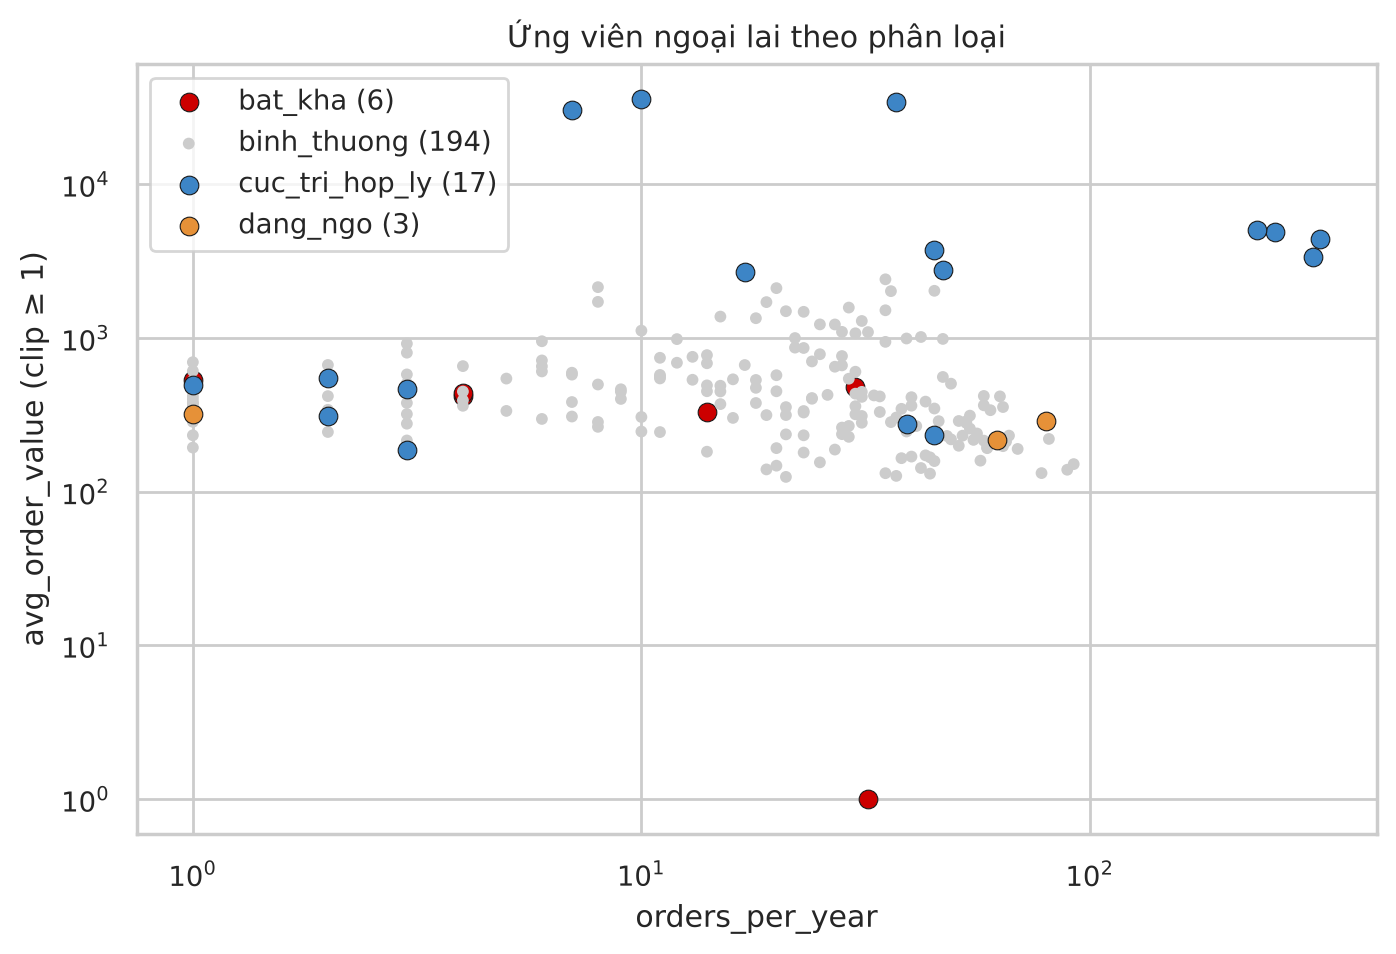

In [20]:
# Hinh: cac ung vien tren mat phang orders - AOV (log)
fig, ax = plt.subplots(figsize=(8, 5))
pal = {"binh_thuong": "#cccccc", "cuc_tri_hop_ly": "#3d85c6", "dang_ngo": "#e69138", "bat_kha": "#cc0000"}
for k_, g in cand.groupby("phan_loai"):
    d = df.loc[g.index]
    ax.scatter(d.orders_per_year, d.avg_order_value.clip(lower=1), s=18 if k_ == "binh_thuong" else 45,
               c=pal[k_], label=f"{k_} ({len(g)})", edgecolor="k" if k_ != "binh_thuong" else "none", lw=.4)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("orders_per_year"); ax.set_ylabel("avg_order_value (clip ≥ 1)")
ax.legend(); ax.set_title("Ứng viên ngoại lai theo phân loại")
savefig(fig, "b_outlier_candidates.png"); plt.show()

### Nhiễu

Với dữ liệu cắt ngang, nhiễu nhỏ không phát hiện được trực tiếp từng giá trị. Có thể ước lượng gián tiếp qua độ phân tán của phần dư quanh một quan hệ kỳ vọng: sessions_per_month tăng theo orders_per_year. Phần dư log được tính trên các dòng không bị phân loại là ngoại lai. Nếu phân phối phần dư có đuôi dày (tỷ lệ std / (1,4826 × MAD) lớn hơn 1 rõ rệt) thì ngoài biến động tự nhiên còn có thành phần nhiễu hoặc giá trị bất thường.

log1p(sessions) = 0.89 + 0.67·log1p(orders) | std phan du = 0.425, MAD chuan hoa = 0.383, ty le = 1.11, kurtosis = 0.96


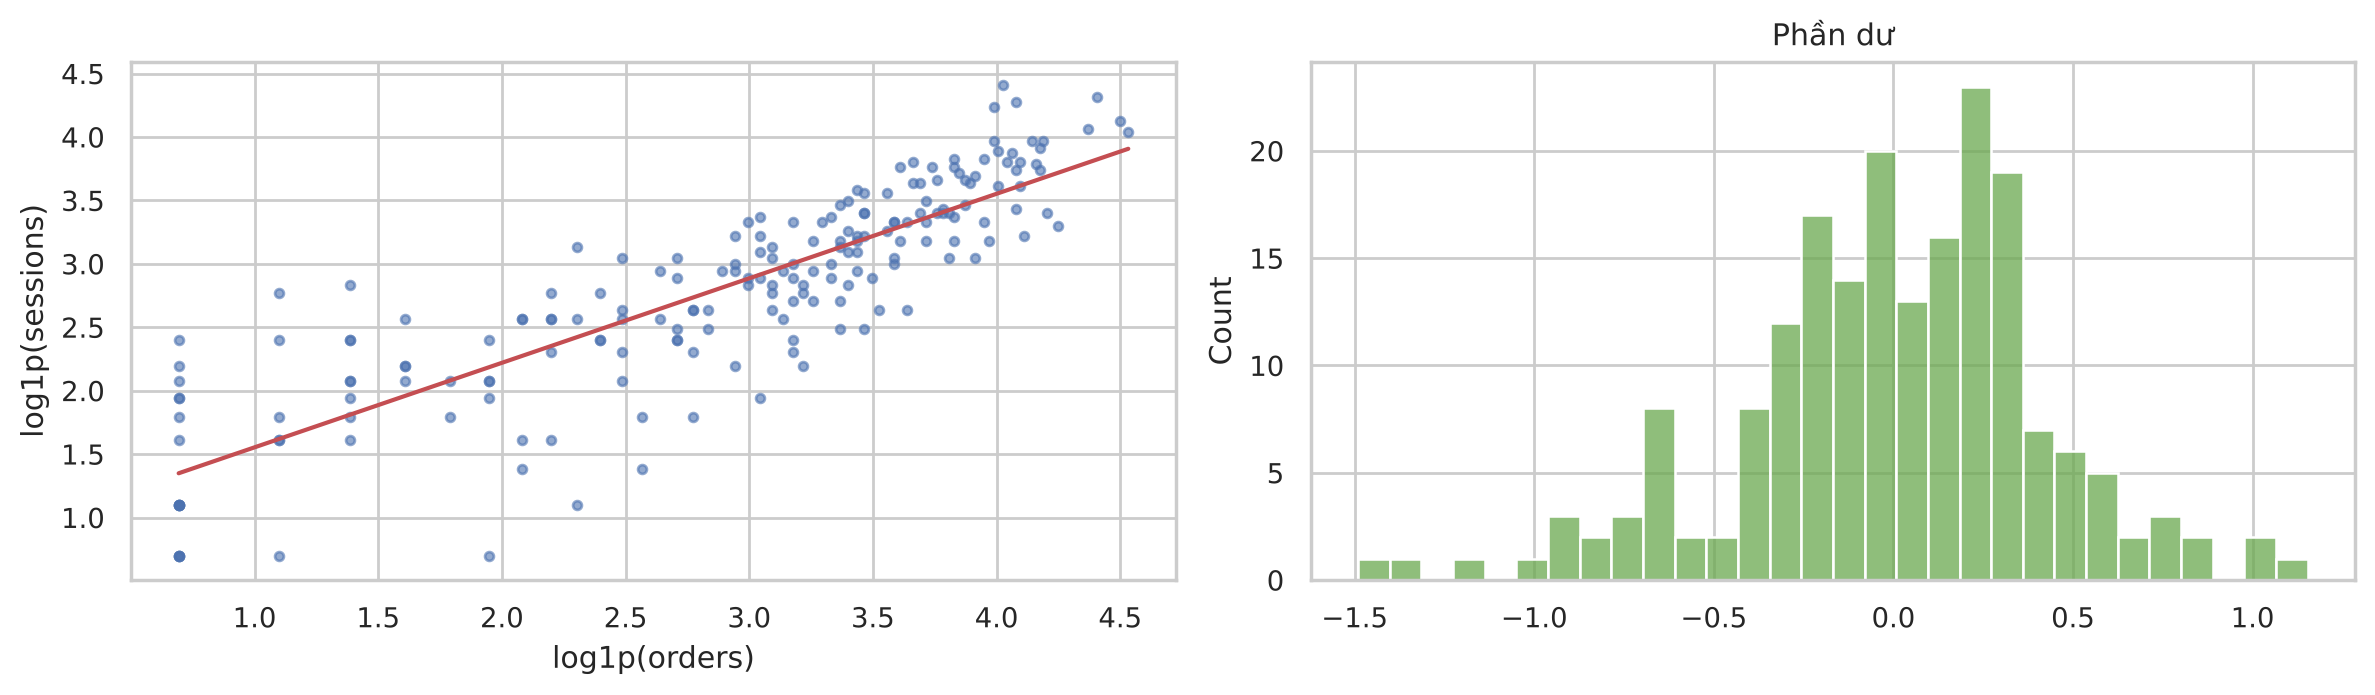

In [21]:
ok = cand.phan_loai.eq("binh_thuong")
d = df.loc[ok, ["orders_per_year", "sessions_per_month"]].astype(float)
lx, ly = np.log1p(d.orders_per_year), np.log1p(d.sessions_per_month)
slope, intercept = np.polyfit(lx, ly, 1)
resid = ly - (slope * lx + intercept)
mad = stats.median_abs_deviation(resid, scale="normal")
print(f"log1p(sessions) = {intercept:.2f} + {slope:.2f}·log1p(orders) | std phan du = {resid.std():.3f}, "
      f"MAD chuan hoa = {mad:.3f}, ty le = {resid.std() / mad:.2f}, kurtosis = {stats.kurtosis(resid):.2f}")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].scatter(lx, ly, s=10, alpha=.6); xs = np.linspace(lx.min(), lx.max(), 50)
axes[0].plot(xs, slope * xs + intercept, "r-"); axes[0].set_xlabel("log1p(orders)"); axes[0].set_ylabel("log1p(sessions)")
sns.histplot(resid, bins=30, ax=axes[1], color="#6aa84f"); axes[1].set_title("Phần dư")
fig.tight_layout(); savefig(fig, "b_noise_residual.png"); plt.show()

**Nhận xét B6.**

- **IQR 1,5 trên thang gốc gắn cờ 64/220 dòng (29%)**, quá nhiều để đều là ngoại lai. Riêng recency có 21 điểm và AOV 25 điểm vượt ngưỡng, chủ yếu do phân phối lệch phải. Trên thang log1p chỉ còn 21 dòng; recency và orders không còn điểm nào. Vì vậy **không được xóa theo IQR thang gốc**.
- **z-score bị hiệu ứng che khuất**: giá trị sessions = 900 làm std tăng từ 23 lên 64, ngưỡng z = 3 từ 93 lên 217. Các giá trị cao khác bị "che". Ngoài ra z-score giả định phân phối gần chuẩn, không phù hợp dữ liệu lệch.
- **Ràng buộc cứng** phát hiện 6 dòng bất khả: tuổi 3 và 150, AOV âm, return_rate 2,5, sessions 900 phiên/tháng, và một khách 18 tuổi có tenure 96 tháng.
- **Ràng buộc mềm và mâu thuẫn hạng**: 3 dòng đáng ngờ. 2 dòng mua ≥ 50 đơn/năm nhưng ≥ 120 ngày chưa mua, và 1 khách Platinum có chi tiêu thuộc 10% thấp nhất (1 đơn/năm, tenure 2 tháng).
- **LOF ổn định** (cùng 7 dòng với k = 10, 20, 30), gắn cờ các khách có cả AOV, thu nhập hoặc số đơn cực lớn nhưng **giá trị khả thi**. Đây là các khách giá trị cao (khách sỉ, siêu VIP), không phải lỗi.
- **Tổng hợp phân loại** (chỉ dựa trên dữ liệu bẩn): 6 bất khả, 3 đáng ngờ, 17 cực trị hợp lý, 194 bình thường. Danh sách lưu ở `reports/tables/b_outlier_candidates.csv` để câu c sử dụng.
- **Nhiễu**: phần dư của log(sessions) theo log(orders) có std 0,425, xấp xỉ MAD chuẩn hóa 0,383 (tỷ lệ 1,11, kurtosis 0,96): phân phối gần chuẩn, không đuôi dày. Vậy nếu có nhiễu thì là nhiễu nhỏ, phân tán đều, **không thể tách khỏi biến động tự nhiên ở từng giá trị**. Xử lý nhiễu ở câu c/d nên theo hướng giảm tác động (log, chuẩn hóa bền vững), không phải sửa từng ô.

## B7. Đối chiếu với dữ liệu sạch và nhật ký can thiệp

Mục này **chỉ dùng để đánh giá** các phát hiện ở B1–B6, không dùng để sửa dữ liệu.

In [22]:
clean = load_raw("customers_clean"); log = load_raw("injection_log")
olog = log[log.kind.str.startswith("outlier")]
truth = olog.drop_duplicates(ID_COL).set_index(ID_COL).kind
is_out = df[ID_COL].isin(truth.index)

def evaluate(name, flag):
    flag = pd.Series(np.asarray(flag), index=df.index)
    tp = (flag & is_out).sum(); fp = (flag & ~is_out).sum(); fn = (~flag & is_out).sum()
    r = {"phuong_phap": name, "so_gan_co": int(flag.sum()), "TP": tp, "FP": fp, "FN": fn,
         "precision": tp / max(flag.sum(), 1), "recall": tp / is_out.sum()}
    for k_ in ["outlier_error", "outlier_logic", "outlier_valid"]:
        ids = truth[truth == k_].index; m = df[ID_COL].isin(ids)
        r[f"recall_{k_.split('_')[1]}"] = f"{(flag & m).sum()}/{m.sum()}"
    return r

ev = pd.DataFrame([
    evaluate("Rang buoc cung", viol_rows), evaluate("Rang buoc mem", soft_rows),
    evaluate("Tier mau thuan", tier_conflict),
    evaluate("IQR 1.5 goc", flag_iqr15.any(axis=1)), evaluate("IQR 3.0 goc", flag_iqr30.any(axis=1)),
    evaluate("IQR 1.5 log", flag_iqrlog.any(axis=1)), evaluate("|z| > 3", flag_z.any(axis=1)),
    evaluate("LOF k=20", flag_lof),
    evaluate("Tong hop (khac binh_thuong)", cand.phan_loai.ne("binh_thuong")),
])
ev.to_csv(TABLES / "b7_outlier_detection_eval.csv", index=False)
ev.round(3)

,phuong_phap,so_gan_co,TP,FP,FN,precision,recall,recall_error,recall_logic,recall_valid
0,Rang buoc cung,6,6,0,9,1.000,0.400,5/5,1/3,0/7
1,Rang buoc mem,2,1,1,14,0.500,0.067,0/5,1/3,0/7
2,Tier mau thuan,1,1,0,14,1.000,0.067,0/5,1/3,0/7
3,IQR 1.5 goc,64,14,50,1,0.219,0.933,5/5,2/3,7/7
4,IQR 3.0 goc,31,12,19,3,0.387,0.800,3/5,2/3,7/7
5,IQR 1.5 log,21,11,10,4,0.524,0.733,4/5,0/3,7/7
6,|z| > 3,21,11,10,4,0.524,0.733,3/5,1/3,7/7
7,LOF k=20,7,7,0,8,1.000,0.467,0/5,0/3,7/7
8,Tong hop (khac binh_thuong),26,15,11,0,0.577,1.000,5/5,3/3,7/7


In [23]:
# Phan loai du doan so voi loai that
true_kind = df[ID_COL].map(truth).fillna("khong_phai_ngoai_lai")
pd.crosstab(true_kind, cand.phan_loai, margins=True)

phan_loai,bat_kha,binh_thuong,cuc_tri_hop_ly,dang_ngo,All
customer_id,,,,,
khong_phai_ngoai_lai,0,194,10,1,205
outlier_error,5,0,0,0,5
outlier_logic,1,0,0,2,3
outlier_valid,0,0,7,0,7
All,6,194,17,3,220


In [24]:
# Cac ngoai lai bi bo sot hoac phan loai sai
miss_df = cand.assign(loai_that=true_kind)[lambda t: (t.loai_that != "khong_phai_ngoai_lai")]
miss_df[["customer_id", "loai_that", "phan_loai", "vi_pham_rang_buoc", "vi_pham_mem", "iqr15_log", "lof_score"]].merge(
    olog.groupby(ID_COL).note.first(), left_on=ID_COL, right_index=True)

,customer_id,loai_that,phan_loai,vi_pham_rang_buoc,vi_pham_mem,iqr15_log,lof_score,note
17,C0018,outlier_valid,cuc_tri_hop_ly,,False,avg_order_value,1.602,khach si
51,C0052,outlier_logic,dang_ngo,,False,,1.145,chi tieu < 2 trieu/nam nhung hang Platinum
66,C0067,outlier_valid,cuc_tri_hop_ly,,False,avg_order_value,1.559,khach si
71,C0072,outlier_valid,cuc_tri_hop_ly,,False,"annual_income,avg_order_value",2.156,sieu VIP
72,C0073,outlier_valid,cuc_tri_hop_ly,,False,"annual_income,avg_order_value",2.538,sieu VIP
110,C0111,outlier_error,bat_kha,"ty le ngoai [0,1]",False,return_rate,0.990,ty le > 1
121,C0122,outlier_valid,cuc_tri_hop_ly,,False,"annual_income,avg_order_value",2.162,sieu VIP
140,C0141,outlier_valid,cuc_tri_hop_ly,,False,"avg_order_value,sessions_per_month",1.618,khach si
166,C0167,outlier_error,bat_kha,sessions > 24*30 hoac < 0,False,sessions_per_month,1.071,so phien bat kha
167,C0168,outlier_error,bat_kha,"age ngoai [18,70]",False,age,1.000,tuoi bat kha


In [25]:
# Dong KHONG phai ngoai lai nhung bi danh dau bat_kha / dang_ngo: xem gia tri sach de hieu vi sao
fp = cand.assign(loai_that=true_kind)[lambda t: (t.loai_that == "khong_phai_ngoai_lai") & t.phan_loai.isin(["bat_kha", "dang_ngo"])]
print(fp[["customer_id", "phan_loai", "vi_pham_rang_buoc", "vi_pham_mem"]])
print(clean.loc[fp.index, ["customer_id", "true_segment", "orders_per_year", "days_since_last_purchase"]])

# Tuong quan: sach so voi ban
cl = clean[NUM_COLS].astype(float)
cmp_rows = []
for x, y in key:
    cmp_rows.append({"cap": f"{x} – {y}", "pearson_sach": cl[x].corr(cl[y]), "pearson_ban": pear.loc[x, y],
                     "spearman_sach": cl[x].corr(cl[y], "spearman"), "spearman_ban": spear.loc[x, y]})
pd.DataFrame(cmp_rows).round(3)

   customer_id phan_loai vi_pham_rang_buoc  vi_pham_mem
90       C0091  dang_ngo                           True
   customer_id true_segment  orders_per_year  days_since_last_purchase
90       C0091   DealHunter               62                       153


,cap,pearson_sach,pearson_ban,spearman_sach,spearman_ban
0,annual_income – avg_order_value,0.827,0.972,0.760,0.771
1,orders_per_year – sessions_per_month,0.871,0.290,0.902,0.879
2,orders_per_year – days_since_last_purchase,-0.510,-0.323,-0.661,-0.659
3,annual_income – orders_per_year,-0.082,0.061,-0.063,-0.041


In [26]:
# Co che thieu: ket luan o B5 so voi co che that trong log
truth_mech = log[log.kind == "missing"].groupby("column").note.first()
sig = mech[mech.p_holm < 0.05].groupby("cot_thieu").bien_so_sanh.apply(list)
pd.DataFrame({"co_che_that": truth_mech,
              "bien_lien_quan_sau_Holm": sig.reindex(truth_mech.index),
              "so_thieu": df[truth_mech.index].isna().sum()})

,co_che_that,bien_lien_quan_sau_Holm,so_thieu
age,MCAR,NaN,11
annual_income,MAR theo tenure_months,NaN,22
preferred_category,MCAR,NaN,9


In [27]:
# Nhieu: do lech phan du sessions ~ orders tren du lieu sach so voi ban (cung tap dong)
dc = clean.loc[ok, ["orders_per_year", "sessions_per_month"]].astype(float)
rc = np.log1p(dc.sessions_per_month) - np.polyval(np.polyfit(np.log1p(dc.orders_per_year), np.log1p(dc.sessions_per_month), 1), np.log1p(dc.orders_per_year))
print(f"std phan du: sach = {rc.std():.3f}, ban = {resid.std():.3f}")
noise = log[log.kind == "noise"].copy()
noise["rel"] = (pd.to_numeric(noise.new_value) - pd.to_numeric(noise.old_value)) / pd.to_numeric(noise.old_value).replace(0, np.nan)
noise.groupby("column").rel.agg(["mean", "std"]).round(4)

std phan du: sach = 0.369, ban = 0.425


,mean,std
column,,
annual_income,0.0014,0.0498
avg_order_value,-0.0063,0.0827
sessions_per_month,-0.0151,0.2864


**Nhận xét B7 (đối chiếu).**

*Đúng với thiết kế:*
- Ràng buộc cứng có precision 1,0: bắt cả 5/5 lỗi đơn biến và 1/3 lỗi logic.
- LOF có precision 1,0 nhưng chỉ bắt 7/7 ngoại lai hợp lệ. Bảng phân loại xếp cả 7 ngoại lai hợp lệ vào `cuc_tri_hop_ly`, không xếp nhầm khách thật nào vào `bat_kha`.
- Phân loại tổng hợp đạt recall 15/15.
- Nhiễu làm tăng std phần dư sessions từ 0,369 lên 0,425 trên cùng tập dòng, khớp với nhiễu cộng khoảng 29% tương đối trên sessions; nhiễu của income (5%) và AOV (8%) đúng như thiết kế.
- Đối chiếu tương quan xác nhận B4: Pearson orders – sessions từ 0,87 (sạch) xuống 0,29 (bẩn); income – AOV từ 0,83 lên 0,97; Spearman gần như không đổi.

*Sai hoặc bỏ sót, cần ghi nhận:*
1. **LOF không bắt được ngoại lai logic nào (0/3)**, trái với giả thuyết đặt ra trước khi chạy. Các ngoại lai logic chỉ sai ở *tổ hợp* hai cột; trong không gian 10 chiều đã chuẩn hóa, chúng vẫn nằm trong vùng mật độ bình thường. Bài học: ngoại lai logic cần kiểm tra bằng **tri thức nghiệp vụ** (ràng buộc), không thể trông chờ vào phương pháp thống kê thuần túy.
2. **Ràng buộc mềm gắn cờ nhầm khách C0091**: trong dữ liệu sạch, đây là khách DealHunter thật, 62 đơn/năm và 153 ngày chưa mua, được sinh ra bởi chính thành phần "ngừng mua" của cơ chế sinh. Điều này lộ ra một **lỗi thiết kế ở câu a**: ngoại lai logic C0205 (80 đơn, 180 ngày) thực chất *không phân biệt được* với hành vi tự nhiên mà câu a cố ý tạo ra. Việc xếp hai trường hợp này vào `dang_ngo` thay vì `bat_kha` là đúng; ở câu c nên giữ lại, không xóa.
3. 10 dòng bình thường bị xếp `cuc_tri_hop_ly` (VIP có AOV cao tự nhiên). Về đánh giá, đây là "FP"; nhưng về nghiệp vụ là đúng vì nhóm này đều được giữ lại.
4. **Kiểm định cơ chế thiếu**: với age và preferred_category (MCAR thật), kết luận đúng. Với income (MAR thật), dấu hiệu đúng hướng nhưng không đạt ý nghĩa sau Holm. Đây là ví dụ về **sai lầm loại II do cỡ mẫu nhỏ**: cơ chế có tồn tại nhưng 22 điểm thiếu không đủ để chứng minh khi kiểm định nhiều giả thuyết cùng lúc.

## B8. Tổng hợp các vấn đề dữ liệu và ảnh hưởng dự kiến đến phân cụm

| # | Vấn đề | Bằng chứng | Ảnh hưởng dự kiến đến phân cụm | Hướng xử lý (câu c/d) |
|---|---|---|---|---|
| 1 | **Chênh lệch thang đo** rất lớn giữa các thuộc tính | IQR của AOV 387,5 so với return_rate 0,115 (khoảng 3.400 lần) | Khoảng cách Euclid, và do đó K-Means, gần như chỉ phản ánh AOV và income; các tỷ lệ hành vi bị bỏ qua | Chuẩn hóa (RobustScaler/StandardScaler) sau biến đổi log |
| 2 | **Lệch phải mạnh và cực trị hợp lý** | skew AOV 8,0, sessions 12,0; 17 dòng cực trị hợp lý, 7 dòng được LOF gắn cờ | Centroid bị kéo về phía cực trị; dễ sinh cụm chỉ 1–3 điểm hoặc gộp VIP với khách sỉ; IQR thang gốc gắn cờ nhầm 29% dữ liệu | log1p; giữ cực trị hợp lý (có thể winsorize ở mức cao); không xóa theo IQR thang gốc |
| 3 | **Giá trị bất khả và vi phạm logic** | 6 dòng vi phạm ràng buộc cứng; 3 dòng đáng ngờ | Điểm sai làm méo khoảng cách và centroid; LOF/IQR không bắt được lỗi logic | Ô bất khả đặt về NaN rồi điền như giá trị thiếu (giữ dòng); dòng đáng ngờ: giữ, ghi chú |
| 4 | **Thuộc tính dư thừa** | orders – sessions Spearman 0,88; tier – chi tiêu Spearman 0,885 | Một khía cạnh hành vi được tính trọng số nhiều lần, các cụm bị lệch theo mức chi tiêu | Lựa chọn thuộc tính hoặc PCA ở câu d |
| 5 | **Pearson không đáng tin** do ngoại lai và quan hệ phi tuyến | orders – sessions Pearson 0,29 so với Spearman 0,88; income – AOV 0,97 so với 0,77 | Nếu chọn thuộc tính dựa trên Pearson sẽ quyết định sai (ví dụ giữ cả orders và sessions vì "tương quan thấp") | Dùng Spearman khi lựa chọn thuộc tính |
| 6 | **Giá trị thiếu, income có dấu hiệu MAR** | 10% income thiếu, tập trung ở khách tenure thấp (p = 0,0018, p_holm = 0,064) | Xóa dòng làm mất 10% dữ liệu và thiên lệch theo nhóm khách mới; K-Means không chạy được khi có NaN | Điền dựa trên biến liên quan (KNN imputer hoặc median theo nhóm tenure); age và category: median, mode |
| 7 | **Dữ liệu hỗn hợp kiểu và thuộc tính không mang cấu trúc** | 4 thuộc tính danh mục; gender, region không liên hệ với thuộc tính khác (mọi p > 0,24) | Cần mã hóa; các biến one-hot không mang thông tin cụm vẫn đóng góp vào khoảng cách, làm loãng cấu trúc cụm | One-hot hoặc ordinal; cân nhắc bỏ gender, region khỏi không gian phân cụm (dùng để mô tả cụm sau) |
| 8 | **Nhiễu nhỏ, phân tán đều** | Phần dư gần chuẩn, std/MAD = 1,11 | Làm ranh giới giữa các cụm mờ hơn, giảm silhouette; không tạo cụm giả | Không sửa từng ô; giảm tác động qua log và chuẩn hóa bền vững |

**Giới hạn của phân tích này:** người phân tích đồng thời là người sinh dữ liệu nên có thể thiên kiến xác nhận; giả thuyết được ghi trước và B7 ghi nhận cả các phát hiện sai (LOF không bắt được lỗi logic, MAR không đạt ý nghĩa, một ngoại lai thiết kế không phân biệt được với hành vi thật). Các ngưỡng của ràng buộc mềm (50 đơn, 120 ngày; 10% chi tiêu thấp nhất) là chủ quan.